# Fatal keywords: khám phá cụm từ gắn với review tệ (rating ≤ 5)

**Câu hỏi nghiên cứu:** Những từ/cụm từ nào xuất hiện nhiều hơn ở nhóm **review tệ: `rating <= 5`**, và chúng phản ánh trải nghiệm nào? Rating được kiểm tra trong khoảng 0–10; “review tệ” là định nghĩa vận hành của bài này, chưa phải quy đổi ra số sao hay nhãn sentiment chuẩn.

**Pipeline:** đọc dữ liệu → Data Quality Audit → lọc comment trùng bằng khóa đơn giản → đo khối lượng văn bản → quan sát rating/độ dài → tạo tập làm việc → chia khám phá/kiểm chứng → đếm 1–3 gram theo review → lọc/xếp hạng → xem mức tập trung → đọc ngữ cảnh → kết luận EDA sơ bộ.

`df_raw` giữ snapshot ban đầu; `df_clean` chỉ bỏ bản sao theo khóa quy ước. Mọi bước phân tích sau lọc lấy dữ liệu từ `df_clean`. Nhãn **rating ≤5 gồm cả rating 0**; nhóm 0 được báo riêng vì chưa xác minh ý nghĩa. Giữ nguyên các thông số n-gram, chia tập và ngưỡng support của pipeline cũ để tập trung đánh giá thay đổi do bộ lọc và ngưỡng rating.

**Quy tắc suy luận:** suy diễn theo định nghĩa để gán nhãn/lọc dòng; quy nạp có điều kiện từ dữ liệu để nhận xét các cụm. Lift biểu thị liên hệ quan sát, không chứng minh một từ gây ra điểm thấp. Các số liệu và nhận xét dưới đây được cập nhật từ lần chạy lại EDA đến hết phần 14; phần 15–18 giữ làm thử nghiệm tiếp theo.

### Cách đọc mạch phân tích

Mỗi bước dưới đây cần trả lời hai câu hỏi khác nhau: **output vừa cho biết điều gì về dữ liệu**, và **điều đó khiến ta chọn bước xử lý/EDA nào tiếp theo**. Các markdown sau output vì vậy tách số liệu quan sát, diễn giải và quyết định. Phần “phản biện” chỉ ra trường hợp có thể làm diễn giải sai và cách kiểm tra lại, thay vì xem mọi số đếm là một kết luận đã được xác nhận.

Chẳng hạn, audit không có comment rỗng cho phép tiếp tục nghiên cứu ngôn ngữ nhưng chưa xác nhận nhãn rating đúng nghĩa; text lặp dẫn tới bộ lọc gọn rồi đo mức tập trung; nhóm rating ≤5 khá rộng dẫn tới so tỷ lệ có điều kiện thay vì chỉ đếm từ; cụm top lift có câu khen dẫn tới yêu cầu đọc ngữ cảnh. Đây là các quyết định được nối thành một chuỗi, không phải những bảng thống kê rời rạc.

**Phân biệt việc đã làm và việc đề xuất:** số liệu hiện có lấy từ output đã chạy trong notebook. “Quyết định trong pipeline” mô tả bước thực sự có ở các cell tiếp theo. “Kiểm chứng tiếp” mô tả việc còn cần làm, chẳng hạn kiểm tra nguồn, đo RAM đỉnh hoặc đánh giá trên validation; không mặc nhiên xem những kiểm tra đó đã hoàn tất. Các tỷ lệ bổ sung trong markdown là phép chia từ số đếm đã hiển thị, không phải kết quả của một mô hình mới.


In [ ]:
!python -m pip install numpy

### Nguồn dữ liệu và đơn vị phân tích

Đọc snapshot `data/processed/18-10-2026.json`. Đơn vị phân tích là một dòng review còn lại sau lọc. Giữ ID ở dạng chuỗi khi đọc để thuận tiện đối chiếu; `df.info()` kiểm tra số dòng, kiểu cột và dữ liệu thiếu trước khi tính chỉ số.

**Vai trò của bước đọc dữ liệu:** trước khi tìm từ khóa, cần xác nhận bài đang nghiên cứu review nào, trên thang điểm nào và với đơn vị đếm nào. Một dòng review không nhất thiết tương đương một khách hàng hoặc một trải nghiệm độc lập: cùng người có thể viết nhiều bài, và nhiều bài có thể cùng phản ánh một shop/sự kiện. Vì vậy, số dòng sẽ là đơn vị đếm vận hành; các bước kiểm tra text/shop phía sau bổ sung góc nhìn về mức độc lập của bằng chứng.

Đọc ID dưới dạng chuỗi phục vụ đối chiếu, không dùng độ lớn số ID làm đặc trưng ngôn ngữ. Sau khi đọc, `info()` đóng vai trò cổng kiểm tra cấu trúc: nếu thiếu `comment_text`/`rating`, pipeline chưa thể trả lời câu hỏi nghiên cứu; nếu đủ hai trường đó, vẫn cần kiểm tra rỗng, miền giá trị và nội dung lặp trước khi phân tích keyword.


In [3]:
import pandas as pd
df = pd.read_json(
    r"D:\FPT\ADY291m\project\data\processed\18-10-2026.json",
    dtype={"source_review_id": "string", "shop_id": "string", "user_pseudo_id": "string"},
)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138131 entries, 0 to 138130
Data columns (total 34 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   review_id          138131 non-null  int64         
 1   source_review_id   124101 non-null  string        
 2   shop_id            138131 non-null  string        
 3   user_pseudo_id     138131 non-null  string        
 4   rating             138131 non-null  float64       
 5   device             138131 non-null  object        
 6   comment_datetime   138131 non-null  object        
 7   comment_text       138131 non-null  object        
 8   num_photos         124101 non-null  float64       
 9   source_platform    138131 non-null  object        
 10  crawled_at         138131 non-null  datetime64[ns]
 11  user_name          138131 non-null  object        
 12  first_seen_at      138131 non-null  datetime64[ns]
 13  shop_name          138131 non-null  object  

#### Insight từ cấu trúc: đủ dữ liệu để bắt đầu, nhưng “không null” chưa đồng nghĩa “đáng tin cậy”

**Quan sát.** Snapshot có **138.131 dòng và 34 cột**. Hai trường cốt lõi `comment_text` và `rating` đều có đủ giá trị không null. `source_review_id` có **124.101 giá trị**, tức thiếu 14.030 dòng, khoảng **10,16%**. Một số thông tin về shop/giá/giờ mở cửa cũng không đầy đủ, trong khi `info()` báo RAM DataFrame khoảng **35,8+ MB**.

**Insight và vai trò.** Bài toán tìm liên hệ giữa ngôn ngữ và rating có đủ cấu trúc tối thiểu để tiếp tục; không cần xóa một review chỉ vì một thuộc tính shop không được dùng trong bài này bị thiếu. Tuy nhiên, phần thiếu ID nguồn làm việc truy nguyên bản ghi kém đầy đủ, còn cột text không null vẫn có thể chứa khoảng trắng hoặc emoji. Bởi vậy, bảng cấu trúc chỉ chứng minh có dữ liệu để kiểm tra tiếp, chưa chứng minh đã có một tập review sạch.

**Quyết định dẫn sang bước sau.** Data Quality Audit sẽ tập trung vào hai điều kiện quyết định việc một review tham gia phân tích: comment thực sự có nội dung và rating đọc được trong 0–10. Việc lọc comment trùng sẽ được tách thành một quy tắc ngắn, thay vì suy từ `review_id` có vẻ đầy đủ rằng không có trùng. Sau đó mới đo độ dài để đánh giá khối lượng xử lý.

**Phản biện và kiểm tra lại.** “Không null” không phát hiện placeholder như `unknown`, cũng không xác nhận ID là duy nhất theo người. Con số 35,8 MB chưa bao gồm mọi bản sao, chuỗi và ma trận phát sinh nên chưa đủ để kết luận sinh 3-gram sẽ an toàn về RAM. Khi thay snapshot, cần kiểm tra lại schema/kiểu dữ liệu; nếu cần quyết định cấu hình tài nguyên thì phải đo khối lượng và RAM lúc chạy, không ngoại suy từ `info()`.

**Cơ sở:** output `df.info()` ngay phía trên; tỷ lệ thiếu ID = 14.030/138.131. Suy luận ở đây là kiểm tra điều kiện cần, không phải chứng minh chất lượng đầy đủ.


### Phase 1 — Khám phá các cụm từ ứng viên
#### 1. Data Quality Audit

Cell dưới kiểm tra comment thiếu/rỗng, rating không đọc được hoặc ngoài 0–10, đồng thời đếm text lặp. Comment được chuẩn hóa NFC, chữ thường và khoảng trắng; giữ nguyên comment gốc để đọc lại.

Đây là thống kê đầu vào, chưa phải quyết định xóa theo text. `corpus` tạm ở bước này sẽ được dựng lại từ `df_clean` sau bộ lọc đơn giản ngay bên dưới. Rating 0 được đếm riêng và vẫn tham gia nhãn ≤5 theo yêu cầu mới.

**Câu hỏi cần giải quyết:** pipeline có đang đưa vào các dòng không tạo được văn bản hoặc nhãn không thể sử dụng không? Cell kiểm tra các lỗi này trước để tránh một bảng lift tính đúng công thức nhưng dựa trên mẫu số sai. Chuẩn hóa NFC/chữ thường/khoảng trắng chỉ gom biểu diễn tương đương theo quy tắc, không sửa lỗi chính tả, không gộp đồng nghĩa và không xóa phủ định.

Kết quả audit sẽ dẫn tới hai nhánh: lỗi comment/rating quyết định điều kiện tham gia tập phân tích; text lặp quyết định bộ lọc comment và cách diễn giải support. Hai nhánh này cần phân biệt vì một review hợp lệ về kiểu dữ liệu vẫn có thể lặp nội dung, còn hai review cùng text vẫn có thể là hai dòng riêng có lý do để giữ.


In [5]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

required_columns = {"rating", "comment_text"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Thiếu các cột: {sorted(missing_columns)}")

# Giữ thêm ID để thuận tiện kiểm tra trùng ở những bước sau
columns = [
    col for col in ["review_id", "shop_id", "rating", "comment_text"]
    if col in df.columns
]
eda = df[columns].copy()

eda["rating_num"] = pd.to_numeric(eda["rating"], errors="coerce")

# Giữ comment gốc; tạo bản chuẩn hóa riêng để thống kê
eda["text_norm"] = (
    eda["comment_text"]
    .astype("string")
    .fillna("")
    .str.normalize("NFC")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

text_missing = eda["comment_text"].isna()
text_empty = eda["text_norm"].eq("")
rating_missing = eda["rating"].isna()
rating_unreadable = (
    eda["rating"].notna() & eda["rating_num"].isna()
)
rating_outside = (
    eda["rating_num"].notna()
    & ~eda["rating_num"].between(0, 10)
)

valid = (
    ~text_empty
    & eda["rating_num"].between(0, 10)
)

audit = pd.Series({
    "Tổng số dòng": len(eda),
    "Comment thiếu": int(text_missing.sum()),
    "Comment rỗng, gồm cả thiếu": int(text_empty.sum()),
    "Rating thiếu": int(rating_missing.sum()),
    "Rating không chuyển được thành số": int(rating_unreadable.sum()),
    "Rating ngoài khoảng 0–10": int(rating_outside.sum()),
    "Dòng có rating = 0": int(eda["rating_num"].eq(0).sum()),
    "Dòng đủ comment và rating hợp lệ": int(valid.sum()),
}, name="Số lượng")

display(audit.to_frame())

# Tập hợp lệ tạm cho audit; phần lọc bên dưới sẽ dựng corpus từ df_clean
corpus = eda.loc[valid].copy()

if corpus.empty:
    raise ValueError("Không có review đáp ứng điều kiện đầu vào.")

duplicate_text = corpus["text_norm"].duplicated(keep=False)

duplicate_summary = pd.Series({
    "Số nội dung khác nhau": corpus["text_norm"].nunique(),
    "Số dòng thuộc nhóm nội dung lặp": int(duplicate_text.sum()),
    "Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung":
        int(corpus["text_norm"].duplicated().sum()),
}, name="Số lượng")

display(duplicate_summary.to_frame())


,Số lượng
Tổng số dòng,138131
Comment thiếu,0
"Comment rỗng, gồm cả thiếu",0
Rating thiếu,0
Rating không chuyển được thành số,0
Rating ngoài khoảng 0–10,0
Dòng có rating = 0,40
Dòng đủ comment và rating hợp lệ,138131


,Số lượng
Số nội dung khác nhau,126236
Số dòng thuộc nhóm nội dung lặp,17619
Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung,11895


In [8]:
with pd.option_context("display.max_colwidth", None):
    display(
        df.loc[df["rating"].eq(0), ["rating", "comment_text"]].head(5)
    )

,rating,comment_text
2905,0.0,Nghe tên chanh ai yu lạ quá tưởng là gì đặt thử thì đúng là trái chanh tên au yu cả nhà ạ. Cứ suy nghĩ cho cao sang chứ tên thật giản dị mà\nChanh thơm chua nhẹ khá hợp cho mấy bạn muốn thử gongcha mà không bị béo nha.
3464,0.0,"Quán có không gian vừa phải. Mình đi trễ còn bánh mì chảo thôi. Chảo nhiều, ăn hoài k hết mà ăn nhiều lại hơi ngán chút, mình nghĩ 1 phần là 2 người ăn cũng được nữa, vì nếu sáng sáng thì ăn ít ít cũng được mà, ăn vừa phải lại ngon ngon hơn nhiều. Giá cả cũng khá được 24 k 1 phần thêm ổ bánh mì. Xíu mại cũng được lắm. \nCó bánh tằm nữa mình chưa ăn bao giờ mà vào quán thấy khá nhiều bạn ăn, chắc lần sau sẽ thử."
4119,0.0,"Lần đầu tiên đi ăn món này, phải nói là đặt niềm tin đúng chỗ luôn. Gọi phần đặc biệt 3 người, nhìn hình vậy thôi chứ 3 đứa ăn hỏng có hết 😝😝\nĐậu bên ngoài giòn, trong mềm thơm kinh khủng. Chả thơm dai vừa ăn, thịt mềm thơm, mắm vừa ăn, thêm cái thấy cưng nữa là tính xèng quán còn cho 3 chục kẹo nữa. 😍😍😍"
6336,0.0,"Lâu lâu đổi địa điểm nên mình ghé đây, đơn giản là vì quán này gần khu nhà ở nhà bạn mình, mà hôm đó trời mưa nên ghé đây ăn luôn, phải nói là món bò lúc lắc cắt khúc ăn dai phải nói luôn, muốn sái quai hàm mà nó còn không tách ra được, cơm chiên ngon, lẩu ok, trời mưa ăn lẩu là sướng phải nói rồi, mà trời mưa ngồi quán này cũng sướng nữa, kiểu không có đc an toàn á, cái ăn trong cảm giác hồi hộp, phiêu lắm kìa. ăn cái lẩu 2 đứa thì ăn không nổi luôn á."
7811,0.0,"QUá nổi tiếng chỉ có một món bánh cống thôi mà luôn luôn khách đông vào rần rần, thường có cả gia đình lớn đi ăn.\nVị trí cũng quen thuộc nhiều người đã biết đi xe hơi vào cũng oki được hết luôn. Có chỗ để xe máy trong nhà. \nKhông gian ổn.\nBánh cống cái bành với lớp vỏ giòn giờn tan luôn con tôm ngon mắt trên mặt lớp nhân mềm thơm bùi bùi với đậu xanh thịt ăn hài hoà vô cùng thêm chút rau xanh ăn kèm nước mắm chua ngọt không thể cưỡng lại được :) :) :) hihi 11k / 1 cái nhe"


#### Insight từ audit: vấn đề chuyển từ lỗi hình thức sang nhãn và mức lặp nội dung

**Quan sát.** Cả **138.131 dòng** qua kiểm tra comment không rỗng và rating trong 0–10: không có comment thiếu/rỗng, rating thiếu, không chuyển được thành số hoặc ngoài miền đang kiểm tra. Vẫn có **40 dòng rating 0**. Về nội dung, có **126.236 text chuẩn hóa khác nhau**, **17.619 dòng thuộc nhóm text lặp (12,76%)**; nếu chỉ giữ một dòng mỗi text thì sẽ bỏ **11.895 dòng (8,61%)**.

**Insight.** Tập này không cần một chiến dịch xử lý null để bắt đầu EDA; những rủi ro đáng quan tâm hơn là **rating có đúng ý nghĩa nghiên cứu không** và **một số câu chữ có đang được đếm nhiều lần không**. Đặc biệt, 17.619 là số dòng tham gia nhóm lặp, còn 11.895 là số dư nếu chỉ giữ một text: hai số không thể thay thế nhau và không số nào tự xác nhận lỗi thu thập.

**Vai trò và quyết định tiếp theo.** Vì không có dòng bị loại bởi kiểm tra hình thức, bước kế tiếp hợp lý là lọc theo khóa comment đơn giản trước khi ước lượng n-gram. Khóa vẫn giữ shop/người/thời điểm/rating để tránh coi mọi câu ngắn giống nhau là một review. Sau lọc cần báo cáo cả số dòng và số text, nhằm biết đã giảm việc lặp đếm hay đã làm mất nội dung. Nhóm rating 0 tiếp tục được giữ theo định nghĩa ≤5, nhưng được đưa vào phần đọc mẫu để kiểm tra giới hạn nhãn.

**Phản biện và kiểm chứng.** Các phép kiểm tra trên chỉ xét một bộ quy tắc; text có nội dung chưa chắc có token chữ/số, và rating trong 0–10 chưa chắc phản ánh mức hài lòng thật. Nếu xóa thẳng 11.895 dòng chỉ dựa vào text, ta có thể làm thay đổi đơn vị đếm từ review sang cách diễn đạt. Nếu giữ nguyên mọi dòng mà bỏ qua lặp, support có thể bị tập trung. Bộ lọc gọn và bảng kiểm tra text/shop sau đó xử lý hai rủi ro ở mức vừa đủ cho EDA, chưa xác minh spam hay gian lận.

**Cơ sở:** hai bảng `audit` và `duplicate_summary` ngay trên; đây là suy diễn từ định nghĩa số dòng lặp và quy nạp có điều kiện về điểm cần khảo sát tiếp.


#### 1A. Lọc comment trùng — một khóa, một lần giữ đầu tiên

Giữ `df_raw`, tạo khóa gồm **nền tảng + shop + người viết + thời điểm đăng + rating + comment chuẩn hóa**. Khi tất cả thành phần đều có giá trị và khóa lặp, giữ dòng đầu tiên. Không bắt buộc `source_review_id` trùng, vì bước này giới hạn nội dung lặp trong tập EDA thay vì chỉ phát hiện lỗi nạp cùng ID.

Giữ review khác người/shop/thời điểm/rating dù câu chữ giống nhau; dòng thiếu thông tin khóa cũng được giữ. Không phân tầng nghi vấn hay dựng thêm quy trình điều tra. Cùng tên người và cùng phút đăng vẫn có thể là hai review riêng: đây là quy ước lọc đơn giản, không phải xác nhận lỗi thu thập. Các dòng loại khỏi tập phân tích nằm trong `dedup_removed`, có thể khôi phục từ `df_raw`.

**Vì sao chọn khóa này trong bài hiện tại?** Ta cần một quyết định dễ kiểm tra, có tác động thực tế lên tập EDA và giữ được review cùng lời nhận xét ở ngữ cảnh khác. `source_review_id` không được bắt buộc trùng vì mục tiêu ở đây là giới hạn những dòng đồng nhất theo khóa nội dung, không chỉ tìm lại cùng ID được nạp hai lần. Dòng đầu được giữ để kết quả tái lập theo thứ tự snapshot; không chọn một dòng vì rating cao/thấp hơn.

**Kỳ vọng cần kiểm tra sau khi chạy:** số dòng giảm nhưng mỗi text chuẩn hóa vẫn có đại diện; tỷ lệ review ≤5 không bị thay đổi lớn chỉ vì quy tắc lọc. Nếu tỷ lệ thay đổi rõ, phải xem các dòng loại trước khi dùng kết quả keyword. Nếu tỷ lệ gần như giữ nguyên, điều đó cho phép tiếp tục pipeline nhưng chưa chứng minh từng quyết định loại đều chính xác.


In [4]:
df_raw = df.copy(deep=True)
dedup_keys = pd.DataFrame(index=df_raw.index)
identity_columns = ["source_platform", "shop_id", "user_pseudo_id", "comment_datetime"]
for col in identity_columns:
    values = df_raw.get(col, pd.Series(pd.NA, index=df_raw.index, dtype="string"))
    normalized = values.astype("string").str.normalize("NFC").str.strip()
    dedup_keys[col] = normalized.mask(normalized.str.lower().isin(
        ["", "unknown", "none", "null", "nan", "nat", "<na>", "n/a"]
    ))
dedup_keys["text_norm"] = eda["text_norm"]
dedup_keys["rating_num"] = eda["rating_num"]
complete_key = (
    dedup_keys.notna().all(axis=1)
    & dedup_keys["text_norm"].ne("")
    & dedup_keys["rating_num"].between(0, 10)
)
duplicate_mask = complete_key & dedup_keys.duplicated(keep="first")
df_clean = df_raw.loc[~duplicate_mask].copy()
dedup_removed = df_raw.loc[duplicate_mask].copy()
dedup_log = pd.DataFrame({"raw_row_id": np.arange(len(df_raw)),
                          "removed": duplicate_mask.to_numpy()})
assert len(df_raw) == len(df_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()
pd.testing.assert_frame_equal(df_raw, df)
print(f"Trước: {len(df_raw):,}; loại theo khóa: {len(dedup_removed):,}; sau: {len(df_clean):,} dòng.")


Trước: 138,131; loại theo khóa: 437; sau: 137,694 dòng.


#### 1B. Kết quả lọc ban đầu và câu hỏi cần kiểm tra trước khi đi tiếp

Cell vừa chạy loại **437/138.131 dòng, khoảng 0,32%**, còn **137.694 dòng**. Mức giảm nhỏ cho thấy quy tắc này chỉ tác động vào một phần hẹp của dữ liệu; không có cơ sở nói rằng phần lớn text lặp đã biến mất hoặc chất lượng ngữ nghĩa đã được giải quyết.

**Insight.** Bộ lọc đã làm đúng vai trò giới hạn những dòng đồng nhất theo khóa, thay vì chuyển toàn bộ tập thành một dòng mỗi câu chữ. Tuy nhiên, số dòng giảm mới trả lời “loại bao nhiêu”, chưa trả lời “loại có làm thay câu hỏi nghiên cứu không”. Cần nhìn tiếp số nội dung khác nhau và cơ cấu nhãn trước/sau.

**Quyết định cho cell tiếp theo.** Báo cáo sẽ so số dòng, số text và số review rating ≤5; biểu đồ chỉ thể hiện quy mô trước/sau. Năm dòng bị loại được hiển thị để có điểm truy vết, không dùng làm mẫu đại diện cho độ chính xác của toàn bộ bộ lọc. Sau khi đối chiếu, dựng `eda` và `corpus` từ `df_clean`, để việc đo khối lượng không vô tình quay lại dùng dữ liệu trước lọc.

**Giới hạn cần giữ.** Khóa cùng tên người/thời điểm không bảo đảm tuyệt đối cùng một trải nghiệm; 437 dòng là số loại theo quy ước EDA, chưa phải 437 lỗi đã xác minh trên nguồn. `df_raw` và `dedup_removed` được giữ để đối chiếu/hoàn tác. Không mở thêm phân tầng điều tra ở đây; việc còn lặp câu chữ sẽ được mô tả trong bước kiểm tra nội dung sau đó.

**Cơ sở:** output bộ lọc ở cell liền trước và cờ `duplicate_mask`; các kết luận về tính chính xác ngoài nguồn vẫn để mở.


Downstream: df_clean → eda → corpus → working → discovery/validation.


,Trước,Sau,Đã loại
Số dòng,138131,137694,437
Text khác nhau,126236,126236,0
"Review rating ≤5, trong 0–10",24453,24371,82


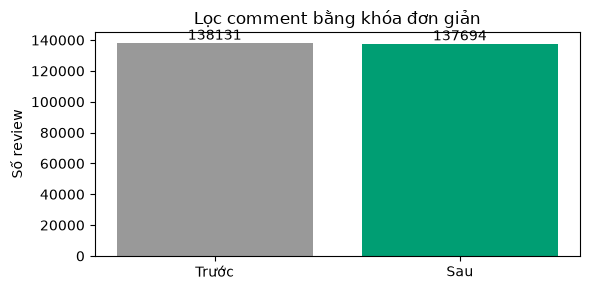

,review_id,shop_id,user_pseudo_id,comment_datetime,rating,comment_text
732,733,sup-moc-can-tho,toannp,2023-06-17T12:38:00,5.0,"Đồ ăn rất ngon, shipper giao hàng nhanh thân t..."
7634,7635,res-beefsteak-kieu-dam-59-nam-ky-khoi-nghia,thuy,2024-08-31T12:39:00,10.0,Tốt
11427,11428,lumos-coffee-cake-tran-hung-dao,thuỷ nguyễn,2024-08-29T12:55:00,10.0,Tuyệt vời
16894,16895,banh-bao-sieu-sach-tran-hoang-na-cu,vũ minh anh,2024-09-27T04:48:00,10.0,Quán làm đồ giao đồ nhanh vãi
17623,17624,banh-bao-sieu-sach-tran-hoang-na-cu,vũ minh anh,2024-09-30T12:52:00,10.0,Hy vọng quán mở thêm nhiều cơ sở nữa chứ đồ ăn...


In [5]:
def describe_filter(part):
    rating_values = pd.to_numeric(part["rating"], errors="coerce")
    texts = (part["comment_text"].astype("string").fillna("")
             .str.normalize("NFC").str.lower().str.replace(r"\s+", " ", regex=True).str.strip())
    return {"Số dòng": len(part), "Text khác nhau": texts.nunique(),
            "Review rating ≤5, trong 0–10": int(rating_values.between(0, 5).sum())}

filter_report = pd.DataFrame({"Trước": describe_filter(df_raw), "Sau": describe_filter(df_clean)})
filter_report["Đã loại"] = filter_report["Trước"] - filter_report["Sau"]
display(filter_report)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Trước", "Sau"], [len(df_raw), len(df_clean)], color=["#999999", "#009E73"])
ax.bar_label(ax.containers[0], fmt="%.0f")
ax.set(title="Lọc comment bằng khóa đơn giản", ylabel="Số review")
plt.tight_layout()
plt.show()
display(dedup_removed[[c for c in ["review_id", "shop_id", "user_pseudo_id", "comment_datetime", "rating", "comment_text"]
                       if c in dedup_removed.columns]].head(5))

eda = df_clean[columns].copy()
eda["rating_num"] = pd.to_numeric(eda["rating"], errors="coerce")
eda["text_norm"] = (eda["comment_text"].astype("string").fillna("")
                    .str.normalize("NFC").str.lower().str.replace(r"\s+", " ", regex=True).str.strip())
valid = eda["text_norm"].ne("") & eda["rating_num"].between(0, 10)
corpus = eda.loc[valid].copy()
if corpus.empty:
    raise ValueError("Không còn review hợp lệ sau lọc.")
pd.testing.assert_frame_equal(corpus[columns], df_clean.loc[valid, columns])
print("Downstream: df_clean → eda → corpus → working → discovery/validation.")


#### Insight từ báo cáo trước/sau: giảm bản sao theo khóa, giữ phạm vi nội dung và gần nguyên cơ cấu nhãn

**Quan sát.** Số dòng giảm **138.131 →137.694**, tức loại **437 dòng (0,32%)**. Số text chuẩn hóa khác nhau giữ nguyên **126.236**. Số review rating ≤5 giảm **24.453 →24.371**, tức **82 dòng**; tỷ lệ nhóm này đều làm tròn khoảng **17,70%** trước/sau.

**Insight.** Bộ lọc đã giảm số lần một khóa xuất hiện mà vẫn giữ ít nhất một đại diện cho mọi nội dung chuẩn hóa trong snapshot này. Đây là dấu hiệu quy tắc đang làm hẹp phần đếm lặp, chưa chuyển bài toán sang chỉ phân tích một tập câu chữ mới. Cơ cấu nhãn gần như không thay đổi ở mức tổng thể nên chưa thấy một biến động lớn của baseline do bộ lọc; tuy nhiên không thể suy ra mọi keyword hiếm cũng giữ nguyên support.

**Vai trò và quyết định sang bước đo khối lượng.** Có thể tiếp tục với `df_clean` làm nguồn duy nhất cho `eda`/`corpus`. Chưa xóa mọi text lặp vì bộ lọc được thiết kế giữ review khác người/shop/thời điểm. Việc còn lặp sẽ được xử lý ở tầng diễn giải support qua bảng text/shop. Bước tiếp theo đo độ dài và lượt n-gram trên chính tập đã lọc, để ước lượng phần việc thực sự pipeline sẽ xử lý.

**Phản biện và cách kiểm tra.** Số text không đổi chỉ chứng minh không mất một chuỗi chuẩn hóa duy nhất, không chứng minh không mất một trải nghiệm hợp lệ. Tỷ lệ tổng thể gần nhau cũng có thể che khác biệt ở shop, khoảng rating hoặc cụm hiếm. Năm mẫu bị loại chỉ giúp truy vết; để kiểm tra một quyết định cụ thể phải đối chiếu cả dòng gốc và dòng còn lại trong cùng khóa. Dữ liệu nguồn không bị ghi đè và có thể khôi phục từ `df_raw`/`dedup_removed`; hiện chưa có xác minh từng bản ghi trên website nguồn.

**Cơ sở:** `filter_report`, biểu đồ số dòng và các mẫu bị loại ngay phía trên; các kết luận chỉ áp dụng cho bộ lọc/snapshot đang chạy.


#### 2. Đo khối lượng văn bản cần xử lý

Từ `corpus` đã lấy từ `df_clean`, đếm độ dài bằng regex giữ các đơn vị chữ/số, kể cả một ký tự. Đây chưa phải tách từ tiếng Việt: “phục vụ” gồm hai đơn vị.

Với comment có $L$ đơn vị, số lượt n-gram độ dài $n$ là $\max(L-n+1,0)$. Tổng lượt 1–3 gram mô tả khối lượng cần duyệt, không phải số cột đặc trưng hay số lần gọi AI. Trung vị và P95/P99 giúp nhìn phần điển hình và đuôi dài trước khi đếm cụm.

**Vai trò của bước này trong lựa chọn cách xử lý.** Số review chỉ mô tả quy mô hàng, còn một bài dài tạo nhiều lượt n-gram hơn một câu ngắn. Đo độ dài vì vậy quyết định liệu cần chú ý tới đuôi dài, dùng ma trận sparse và đếm theo lô, chứ không chỉ quyết định một ngưỡng cắt comment.

Các phép đo cũng tách hai vấn đề: review không có token sẽ không cung cấp đặc trưng cho cách đếm hiện tại; review dài vẫn có thể chứa nhiều ngữ cảnh hữu ích. Bước tiếp theo cần xem cả phân phối lẫn ví dụ, tránh dùng một thống kê cực trị để xóa dữ liệu ngay.


In [6]:
# Quy tắc này sẽ được giữ nhất quán khi tạo n-gram sau đó
TOKEN_PATTERN = r"(?u)\b\w+\b"
token_regex = re.compile(TOKEN_PATTERN)

corpus["n_tokens"] = corpus["text_norm"].map(
    lambda text: len(token_regex.findall(text))
)
corpus["n_chars"] = corpus["text_norm"].str.len()

length_summary = (
    corpus[["n_tokens", "n_chars"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .rename(columns={
        "n_tokens": "Số đơn vị văn bản",
        "n_chars": "Số ký tự",
    })
    .round(1)
)

display(length_summary)

print(
    "Comment có nội dung nhưng không có đơn vị chữ/số:",
    int(corpus["n_tokens"].eq(0).sum())
)

# Với L đơn vị, số lượt n-gram độ dài n là max(L - n + 1, 0)
ngram_volume = pd.DataFrame([
    {
        "Loại": f"{n}-gram",
        "Tổng lượt cụm cần xét":
            int((corpus["n_tokens"] - n + 1).clip(lower=0).sum()),
    }
    for n in [1, 2, 3]
])

display(ngram_volume)

total_occurrences = ngram_volume["Tổng lượt cụm cần xét"].sum()
print(f"Tổng lượt ứng viên 1–3 gram cần xét: {total_occurrences:,}")

Comment có nội dung nhưng không có đơn vị chữ/số: 167
Tổng lượt ứng viên 1–3 gram cần xét: 32,981,545


,Số đơn vị văn bản,Số ký tự
count,137694.0,137694.0
mean,80.8,353.2
std,66.5,290.9
min,0.0,1.0
50%,69.0,304.0
90%,154.0,673.0
95%,195.0,851.0
99%,311.0,1368.0
max,1136.0,5258.0


,Loại,Tổng lượt cụm cần xét
0,1-gram,11130851
1,2-gram,10993324
2,3-gram,10857370


#### Insight về khối lượng: tài nguyên phụ thuộc độ dài, còn bài dài chưa phải dữ liệu xấu

**Quan sát.** Trên **137.694 review**, độ dài trung bình **80,8** đơn vị, trung vị **69**, P95 **195**, P99 **311** và cực đại **1.136**. Tổng lượt cần duyệt gồm **11.130.851 lượt 1-gram, 10.993.324 lượt 2-gram, 10.857.370 lượt 3-gram**, cộng **32.981.545 lượt**. Có **167 comment có nội dung nhưng không có token chữ/số**, khoảng **0,12%**.

**Insight.** Trung bình lớn hơn trung vị và khoảng cách từ P99 đến cực đại cho thấy một phần đuôi dài làm tăng khối lượng. Khoảng 1% phía trên mốc P99 không đại diện comment điển hình; lấy độ dài cực đại để mô tả mọi review sẽ phóng đại lượng xử lý. Ngược lại, chỉ nhìn trung vị sẽ bỏ qua những bài rất dài. Tổng 32,98 triệu lượt là số lần xét cửa sổ n-gram, không phải 32,98 triệu cụm khác nhau hay cột đặc trưng.

**Vai trò và quyết định trong pipeline.** Các con số này hỗ trợ giữ thiết kế `binary=True`, ma trận sparse và đếm theo lô ở phần 7: một bài dài không được tăng support chỉ bằng lặp lại cùng cụm nhiều lần, và không cần giữ ma trận toàn tập cùng lúc khi cộng bộ đếm. Trước khi đến bước đó, histogram và mẫu dài/không token giúp xác định phần đuôi là gì. Hiện **không cắt bài theo độ dài**, vì chưa có bằng chứng độ dài tự nó là lỗi.

**Phản biện và kiểm chứng.** Regex đếm đơn vị chữ/số chứ chưa tách nghĩa tiếng Việt; dấu câu bị bỏ qua nên có thể tạo cụm băng qua ranh giới câu. 167 dòng không có token không đồng nghĩa vô giá trị: emoji vẫn có thể biểu đạt cảm xúc. Chúng chỉ không tham gia phương pháp n-gram đang dùng. Các thiết kế sparse/theo lô là lựa chọn vận hành đã có trong code, chưa phải bằng chứng RAM đỉnh đủ thấp; nếu cần quyết định tài nguyên cụ thể, phải benchmark và đo RAM lúc chạy.

**Cơ sở:** `length_summary`, `ngram_volume` và số comment 0 token ngay trên; nhận định đuôi phải là mô tả phân phối, chưa là nguyên nhân làm review tệ.


#### 3. Quan sát rating và độ dài comment

Histogram rating cho biết cơ cấu điểm và vị trí ngưỡng review tệ **5**. Đường ngưỡng chỉ thể hiện định nghĩa đang dùng; histogram chia khoảng nên số review ≤5 cần xem ở bảng đếm.

Biểu đồ độ dài dùng trục logarithm và chỉ vẽ comment có token dương. Hai biểu đồ là hai phân phối riêng, chưa chứng minh review tệ dài hơn review >5. Phần đếm keyword dùng hiện diện có/không trong từng review để hạn chế việc một bài dài lặp từ nhiều lần.

**Câu hỏi dẫn dắt:** nhóm điểm cần giải thích có hiếm tới mức bảng từ phổ biến toàn tập bị nhóm >5 lấn át không? Đồng thời, có đủ bằng chứng để đặt ngưỡng độ dài hay vẫn chỉ nên đọc mẫu? Đặt hai biểu đồ cạnh nhau để trả lời hai quyết định đó; chưa dùng chúng để kết luận quan hệ giữa rating và độ dài.


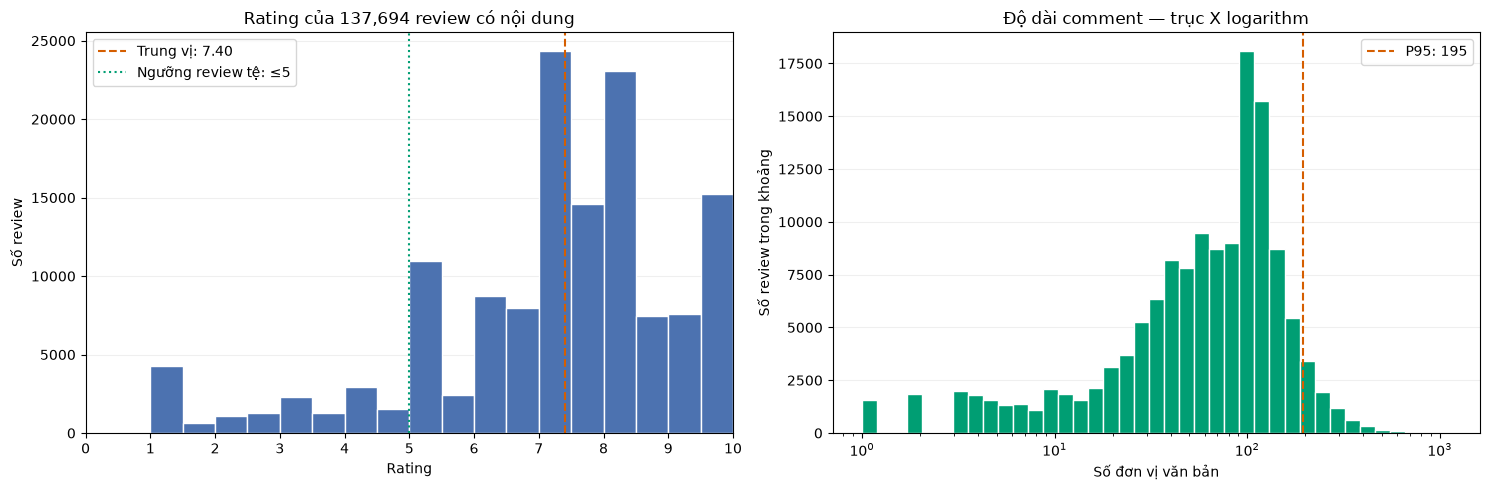

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Phân phối rating
rating = corpus["rating_num"]

axes[0].hist(
    rating,
    bins=np.linspace(0, 10, 21),
    color="#4C72B0",
    edgecolor="white",
)
axes[0].axvline(
    rating.median(),
    color="#D55E00",
    linestyle="--",
    label=f"Trung vị: {rating.median():.2f}",
)
axes[0].set(
    title=f"Rating của {len(corpus):,} review có nội dung",
    xlabel="Rating",
    ylabel="Số review",
    xlim=(0, 10),
    xticks=range(11),
)
axes[0].axvline(5, color="#009E73", linestyle=":", label="Ngưỡng review tệ: ≤5")
axes[0].legend()

# 2. Phân phối độ dài; loại 0 khỏi riêng biểu đồ logarithm
positive_lengths = corpus.loc[
    corpus["n_tokens"] > 0, "n_tokens"
]

if not positive_lengths.empty:
    length_bins = np.geomspace(
        1, positive_lengths.max() + 1, 40
    )

    axes[1].hist(
        positive_lengths,
        bins=length_bins,
        color="#009E73",
        edgecolor="white",
    )
    axes[1].set_xscale("log")

    p95 = positive_lengths.quantile(0.95)
    axes[1].axvline(
        p95,
        color="#D55E00",
        linestyle="--",
        label=f"P95: {p95:.0f}",
    )
    axes[1].legend()
else:
    axes[1].text(
        0.5, 0.5, "Không có đơn vị chữ/số",
        ha="center", va="center",
        transform=axes[1].transAxes,
    )

axes[1].set(
    title="Độ dài comment — trục X logarithm",
    xlabel="Số đơn vị văn bản",
    ylabel="Số review trong khoảng",
)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


#### Insight từ phân phối: cần so tỷ lệ theo nhóm, không tìm keyword bằng tần suất toàn tập

**Quan sát.** Rating trung vị **7,40**, cao hơn ngưỡng 5 đang dùng. Có **24.371/137.694 review ≤5, khoảng 17,70%** trước khi loại comment không có token; phần còn lại chiếm khoảng 82,30%. Histogram độ dài vẫn có đuôi phải và P95 gần **195** đơn vị.

**Insight cho bài toán keyword.** Nhóm review tệ là thiểu số. Một từ xuất hiện nhiều toàn tập có thể phổ biến chỉ vì xuất hiện trong nhiều review >5, không phải vì nó giải thích nhóm ≤5. Vì thế, chỉ xếp tần suất tuyệt đối sẽ dễ chọn cách diễn đạt phổ thông. Cần biết tỷ lệ review tệ khi có cụm so với tỷ lệ tệ nền, đồng thời cụm phủ được bao nhiêu review tệ.

**Quyết định dẫn hướng EDA.** Chưa cắt comment dài; sẽ đọc mẫu đuôi dài và tiếp tục dùng hiện diện nhị phân theo review. Với nhãn, giữ ngưỡng ≤5 theo yêu cầu nhưng đếm chính xác các mức/ngưỡng ở bước 5 thay vì suy từ chiều cao histogram. Sau đó tạo ứng viên từ nhóm ≤5 và đếm lại trên cả hai nhóm, để phần 8 có đủ số liệu tính lift/độ phủ.

**Phản biện.** Histogram chia khoảng, nên một cột gần 5 không trực tiếp cho số review bằng 5 hoặc ≤5; phải dùng bảng đếm. Hai biểu đồ riêng không cho biết review tệ có dài hơn nhóm >5, và gần 82% review >5 không có nghĩa 82% văn bản chỉ nói tích cực. P95 là mốc mô tả, chưa phải tiêu chuẩn chất lượng. Nếu cần kiểm tra ảnh hưởng độ dài tới kết quả keyword, nên so theo nhóm rating hoặc các dải độ dài; bước đó chưa được chạy ở đây.

**Cơ sở:** histogram, median và số đếm từ `corpus`. Baseline cho lift vẫn phải lấy riêng trên discovery sau các điều kiện token/chia tập.


#### 4. Kiểm tra các nội dung lặp còn lại

Bảng dưới chỉ **mô tả** text lặp sau bộ lọc đơn giản: số dòng, shop, rating và review ID khác nhau. Không xóa thêm theo text tại đây. Cùng câu chữ ở các shop/người viết/thời điểm khác nhau vẫn có thể là các review riêng.

`review_id` nội bộ không lặp chưa chứng minh nội dung không sao chép. Mục đích của bảng là nhận diện mức tập trung có thể ảnh hưởng support/lift, không điều tra sâu từng trường hợp hay gán nhãn spam.

**Điểm cần phân biệt sau bước lọc:** bộ lọc chỉ gộp khóa hoàn toàn giống, còn bảng ở đây gom mọi review có cùng câu chữ. Nếu một câu ngắn xuất hiện ở rất nhiều shop, đó là tín hiệu rằng xóa theo text toàn cục có thể loại thông tin về nhiều review. Nếu một text dài tập trung tại một shop, đó là tín hiệu cần thận trọng khi diễn giải support; chưa đủ để mở thêm một quy tắc xóa.

Kết quả sẽ quyết định có cần nhìn bằng chứng theo số text/shop khi đánh giá keyword không. Chưa cần biết cụm nào là “fatal” ở bước này; trước hết cần biết tại sao số dòng hỗ trợ có thể khác số cách diễn đạt độc lập.


In [8]:
# Chỉ kiểm tra các dòng có nội dung lặp
duplicate_rows = corpus.loc[
    corpus["text_norm"].duplicated(keep=False)
].copy()

aggregation = {
    "so_dong": ("rating_num", "size"),
    "so_rating_khac_nhau": ("rating_num", "nunique"),
    "rating_nho_nhat": ("rating_num", "min"),
    "rating_lon_nhat": ("rating_num", "max"),
}

if "shop_id" in corpus.columns:
    aggregation["so_shop"] = ("shop_id", "nunique")

if "review_id" in corpus.columns:
    aggregation["so_review_id"] = ("review_id", "nunique")

duplicate_groups = (
    duplicate_rows
    .groupby("text_norm")
    .agg(**aggregation)
    .sort_values("so_dong", ascending=False)
    .reset_index()
)

# Rút ngắn riêng phần hiển thị; không cắt nội dung trong corpus
duplicate_preview = duplicate_groups.head(25).copy()
duplicate_preview["text_norm"] = duplicate_preview["text_norm"].map(
    lambda text: text[:180] + ("..." if len(text) > 180 else "")
)

display(
    duplicate_preview.rename(columns={
        "text_norm": "Nội dung — xem trước",
        "so_dong": "Số dòng",
        "so_rating_khac_nhau": "Số rating khác nhau",
        "rating_nho_nhat": "Rating nhỏ nhất",
        "rating_lon_nhat": "Rating lớn nhất",
        "so_shop": "Số shop khác nhau",
        "so_review_id": "Số review ID khác nhau",
    })
)

# Tổng quan về ID lặp, chưa tự động loại bỏ
if "review_id" in corpus.columns:
    review_ids = (
        corpus["review_id"].astype("string").str.strip()
    )

    known_id = (
        review_ids.notna()
        & ~review_ids.str.lower().isin(
            ["", "unknown", "none", "null", "nan"]
        )
    ).fillna(False)

    repeated_id = review_ids.loc[known_id].duplicated(keep=False)

    print(
        "Số dòng có review_id hợp lệ bị lặp:",
        int(repeated_id.sum())
    )
    print(
        "Số review_id khác nhau bị lặp:",
        review_ids.loc[known_id].loc[repeated_id].nunique()
    )

Số dòng có review_id hợp lệ bị lặp: 0
Số review_id khác nhau bị lặp: 0


,Nội dung — xem trước,Số dòng,Số rating khác nhau,Rating nhỏ nhất,Rating lớn nhất,Số shop khác nhau,Số review ID khác nhau
0,ngon,574,22,5.0,10.0,134,574
1,nem nướng ngon,395,6,5.0,10.0,3,395
2,tốt,284,20,3.0,10.0,35,284
3,rất ngon,260,17,5.0,10.0,58,260
4,tuyệt vời,191,19,5.0,10.0,71,191
5,10 điểm cho chất lượng,166,11,5.0,10.0,8,166
6,vừa miệng,152,12,5.0,10.0,1,152
7,ngon tuyệt,137,15,5.0,10.0,34,137
8,dịch vụ tốt,126,12,5.0,10.0,24,126
9,món ăn ngon,109,12,4.8,10.0,44,109


#### Insight từ text lặp: bộ lọc bản ghi và kiểm tra mức tập trung giải quyết hai việc khác nhau

**Quan sát.** Sau lọc còn **16.846 dòng thuộc 5.388 nhóm text lặp**, khoảng **12,23%** tập `corpus`. “**Ngon**” đứng đầu với **574 review tại 134 shop**. Kiểm tra `review_id` báo không có ID nội bộ hợp lệ bị lặp.

**Insight.** Cùng một câu ngắn có thể xuất hiện tại nhiều địa điểm và vẫn là những dòng riêng theo khóa đang dùng. Do đó, text lặp còn tồn tại không tự chứng minh bộ lọc vừa làm là sai. Nhưng một cụm có support lớn vẫn có thể được nâng lên bởi ít cách diễn đạt lặp lại: **đếm review** và **đếm nội dung khác nhau** trả lời hai câu hỏi khác nhau.

**Vai trò đối với hướng giải quyết.** Bài vẫn dùng review làm đơn vị support; không đổi sang một dòng mỗi text ở bước này vì sẽ thay đơn vị phân tích và làm mất thông tin về bối cảnh. Hệ quả là khi đã có shortlist keyword, phải xem thêm số text khác nhau, tỷ trọng text lớn nhất và phân tán shop ở phần 11. Đây là lý do có bước kiểm tra bằng chứng sau khi xếp hạng, dù đã lọc comment trước tokenization.

**Quyết định bước tiếp theo.** Giữ các text còn lặp, chuyển sang đọc mẫu rating 0/emoji/bài dài và chốt tập làm việc. Khi chia discovery/validation, các dòng cùng `text_norm` phải ở cùng phía; nếu không, câu chữ giống nhau có thể xuất hiện cả ở nơi tìm và nơi kiểm chứng ứng viên.

**Phản biện và kiểm tra lại.** Khác ID nội bộ không chứng minh khác review nguồn, khác người hay không sao chép; ngược lại, cùng text cũng không chứng minh spam. Bảng top 25 được chọn theo mức lặp, không đại diện mọi review. Chưa đo tác động của việc giới hạn mỗi text một đóng góp lên lift, nên chỉ ghi nhận rủi ro và theo dõi mức tập trung, không tuyên bố đã loại hết ảnh hưởng lặp.

**Cơ sở:** `duplicate_rows`, `duplicate_groups` và output kiểm tra `review_id` ở cell liền trước.


#### 5. Đọc mẫu và đối chiếu các ngưỡng rating

Đọc vài review rating 0, comment không có token chữ/số và các bài dài nhất để kiểm tra giới hạn dữ liệu/tokenizer. Đây là mẫu có chủ đích, không đại diện toàn tập.

Bảng ngưỡng 1–5 giữ vai trò tham khảo; **ngưỡng sử dụng từ đây là ≤5, gồm rating 0**. Bảng vẫn in thêm số đếm không gồm 0 để dễ đối chiếu, nhưng không dùng cột đó để tạo nhãn chính.

**Vai trò của việc đọc mẫu:** thống kê giúp xác định chỗ cần nhìn, còn văn bản giúp phân biệt giới hạn tokenizer, nội dung nhiều khía cạnh và khả năng nhãn không đồng nghĩa cảm xúc. Mẫu ở đây dùng để phát hiện vấn đề có thể ảnh hưởng diễn giải, không tự thay thế kiểm chứng nguồn.

Bảng ngưỡng cũng trả lời một câu hỏi thiết kế: mở từ ≤2 sang ≤5 đưa thêm loại review nào vào nhóm đích? Nếu lượng tăng tập trung sát 5, kết quả keyword mới có thể phản ánh đánh giá vừa phải hoặc khen/chê pha trộn; khi đó cần ưu tiên đọc ngữ cảnh và tránh gọi mọi token gắn với ≤5 là tiêu cực.


In [9]:
def show_review_examples(rows, title, n=5):
    print(f"\n{title} — tổng cộng {len(rows):,} dòng")

    if rows.empty:
        return

    columns = [
        col for col in
        ["review_id", "shop_id", "rating_num", "n_tokens", "comment_text"]
        if col in rows.columns
    ]

    preview = rows.head(n)[columns].copy()
    preview["comment_text"] = preview["comment_text"].astype(str).map(
        lambda text: text[:600] + ("..." if len(text) > 600 else "")
    )

    # Chỉ thay đổi cách hiển thị trong khối này
    with pd.option_context(
        "display.max_colwidth", 650,
        "display.max_columns", None
    ):
        display(preview)


show_review_examples(
    corpus.loc[corpus["rating_num"].eq(0)],
    "Review rating = 0",
)

show_review_examples(
    corpus.loc[corpus["n_tokens"].eq(0)],
    "Comment không có đơn vị chữ/số",
)

show_review_examples(
    corpus.sort_values("n_tokens", ascending=False),
    "Các comment dài nhất",
    n=3,
)

# Khảo sát trên tập có thể tạo n-gram
text_usable = corpus.loc[corpus["n_tokens"] > 0]

threshold_summary = []

for threshold in [1, 2, 3, 4, 5]:
    low_mask = text_usable["rating_num"].le(threshold)

    threshold_summary.append({
        "Ngưỡng khảo sát": f"Rating ≤ {threshold}",
        "Số review thấp, gồm rating 0": int(low_mask.sum()),
        "Số review thấp, không gồm rating 0": int(
            (
                low_mask
                & text_usable["rating_num"].gt(0)
            ).sum()
        ),
        "Tỷ lệ thấp, gồm rating 0 (%)":
            round(low_mask.mean() * 100, 2),
    })

display(pd.DataFrame(threshold_summary))



Review rating = 0 — tổng cộng 40 dòng

Comment không có đơn vị chữ/số — tổng cộng 167 dòng

Các comment dài nhất — tổng cộng 137,694 dòng


,review_id,shop_id,rating_num,n_tokens,comment_text
2905,2906,gong-cha-tra-ca-phe-vincom-xuan-khanh,0.0,52,Nghe tên chanh ai yu lạ quá tưởng là gì đặt thử thì đúng là trái chanh tên au yu cả nhà ạ. Cứ suy nghĩ cho cao sang chứ tên thật giản dị mà\nChanh thơm chua nhẹ khá hợp cho mấy bạn muốn thử gongcha mà không bị béo nha.
3464,3465,banh-tam-xiu-mai-banh-mi-chao,0.0,97,"Quán có không gian vừa phải. Mình đi trễ còn bánh mì chảo thôi. Chảo nhiều, ăn hoài k hết mà ăn nhiều lại hơi ngán chút, mình nghĩ 1 phần là 2 người ăn cũng được nữa, vì nếu sáng sáng thì ăn ít ít cũng được mà, ăn vừa phải lại ngon ngon hơn nhiều. Giá cả cũng khá được 24 k 1 phần thêm ổ bánh mì. Xíu mại cũng được lắm. \nCó bánh tằm nữa mình chưa ăn bao giờ mà vào quán thấy khá nhiều bạn ăn, chắc lần sau sẽ thử."
4119,4120,3-hien-bun-dau-mam-tom-pham-ngu-lao,0.0,68,"Lần đầu tiên đi ăn món này, phải nói là đặt niềm tin đúng chỗ luôn. Gọi phần đặc biệt 3 người, nhìn hình vậy thôi chứ 3 đứa ăn hỏng có hết 😝😝\nĐậu bên ngoài giòn, trong mềm thơm kinh khủng. Chả thơm dai vừa ăn, thịt mềm thơm, mắm vừa ăn, thêm cái thấy cưng nữa là tính xèng quán còn cho 3 chục kẹo nữa. 😍😍😍"
6336,6337,pho-nuong-102,0.0,108,"Lâu lâu đổi địa điểm nên mình ghé đây, đơn giản là vì quán này gần khu nhà ở nhà bạn mình, mà hôm đó trời mưa nên ghé đây ăn luôn, phải nói là món bò lúc lắc cắt khúc ăn dai phải nói luôn, muốn sái quai hàm mà nó còn không tách ra được, cơm chiên ngon, lẩu ok, trời mưa ăn lẩu là sướng phải nói rồi, mà trời mưa ngồi quán này cũng sướng nữa, kiểu không có đc an toàn á, cái ăn trong cảm giác hồi hộp, phiêu lắm kìa. ăn cái lẩu 2 đứa thì ăn không nổi luôn á."
7811,7812,banh-cong-co-ut-ly-tu-trong,0.0,106,"QUá nổi tiếng chỉ có một món bánh cống thôi mà luôn luôn khách đông vào rần rần, thường có cả gia đình lớn đi ăn.\nVị trí cũng quen thuộc nhiều người đã biết đi xe hơi vào cũng oki được hết luôn. Có chỗ để xe máy trong nhà. \nKhông gian ổn.\nBánh cống cái bành với lớp vỏ giòn giờn tan luôn con tôm ngon mắt trên mặt lớp nhân mềm thơm bùi bùi với đậu xanh thịt ăn hài hoà vô cùng thêm chút rau xanh ăn kèm nước mắm chua ngọt không thể cưỡng lại được :) :) :) hihi 11k / 1 cái nhe"


,review_id,shop_id,rating_num,n_tokens,comment_text
53,54,ga-ran-va-mi-y-jollibee-duong-30-thang-4,7.6,0,😍
56,57,ga-ran-va-mi-y-jollibee-duong-30-thang-4,8.0,0,😍
519,520,ga-ran-kfc-vinmart-vinatex-can-tho,7.8,0,😐😐😐
785,786,mi-y-chung-cu-34-nguyen-khuyen,7.8,0,🤩
820,821,thu-hien-bun-mang-bun-cari,8.6,0,😍


,review_id,shop_id,rating_num,n_tokens,comment_text
25846,25847,hanuri-quan-an-han-quoc-cong-hoa,10.0,1136,"Dưới đây là một bài viết chi tiết về trải nghiệm ẩm thực tại Hanuri – Quán ăn Hàn Quốc, nơi mang đến một hương vị đặc trưng của xứ sở kim chi với giá cả hợp lý và phong cách phục vụ nhanh chóng. Bài viết sẽ xoay quanh hương vị, trải nghiệm thực tế và so sánh với các quán khác để bạn có cái nhìn toàn diện hơn.\n\n---\n\nHanuri – Chuyến du hành vị giác đến Hàn Quốc giữa lòng Sài Gòn\n\nẨm thực Hàn Quốc từ lâu đã chiếm một vị trí đặc biệt trong lòng thực khách***nhờ vào sự hài hòa giữa màu sắc, hương vị và cách trình bày món ăn. Nếu bạn là một tín đồ của kimbap, bibimbap, tokbokki hay gà rán sốt cay, t..."
48169,48170,banh-canh-hem-pham-van-chi,7.4,1105,"Khi báo Thanh Niên đến chỗ cô làm phỏng vấn, dư luận bắt đầu rẽ nhánh và chia làm hai quan điểm rõ rệt.🤔\n\nVới cái giá 80-100-150 và thậm chí 300k cho một tô bánh canh hẻm, người đồng ý, kẻ cười chê.\n\nĐến cái level mà cứ hôm nay lên bài khen là hôm sau có bài phốt... Giằng xé cãi nhau ỏm củ tỏi...\nĐiều này khiến mình thực sự rất tò mò và thậm chí là hoang mang đấu tranh tâm lý nên thử hay không.\n\nMột phần là hiệu ứng đám đông cũng khiến mình lo sợ rằng sau khi được nổi tiếng, chất lượng bị sụt giảm sẽ làm đánh giá bị thiếu độ xác thực.\n\nNhưng sau khi cắn đá, lội 10km từ quận 1 lên quận 6 để mua..."
68613,68614,phong-cua-cay-su-quan,2.0,1098,"Chuyện là tối qua Noel ngày 24-12. Em với người yêu có đi vô quán PHONG CUA- THANH ĐA để ăn. Do đọc review thấy khá được và cũng gần nên tụi em quyết định vào đó ăn. Thế nhưng thái độ phục vụ của nhân viên quán rất rất tệ. Những gì em nói sau đây hoàn toàn 100% là sự thật, không hề nói sai, nói quá 1 lời nào\n\nĐầu tiên, bước vô bàn ăn phục vụ chỉ đưa 2 cái bát và 2 đôi đũa đặt vẻn vẹn trên bàn. Không hề đưa khăn ướt hay hỏi khách hàng gọi nước hay không. Đến khi em kêu nước 2 lon pepsi thì đưa đúng 2 lon mà kg hề có ly nước nào. Thử hỏi vậy thì uống bằng cách nào? Chưa dừng ở đó, tụi em nói cái..."


,Ngưỡng khảo sát,"Số review thấp, gồm rating 0","Số review thấp, không gồm rating 0","Tỷ lệ thấp, gồm rating 0 (%)"
0,Rating ≤ 1,3888,3848,2.83
1,Rating ≤ 2,5322,5282,3.87
2,Rating ≤ 3,7936,7896,5.77
3,Rating ≤ 4,11563,11523,8.41
4,Rating ≤ 5,24347,24307,17.70


#### Insight từ đọc mẫu và các ngưỡng: nhóm ≤5 rộng hơn nhiều so với nhóm bất mãn cực đoan

**Quan sát định lượng.** Trên **137.527 review có token**, số review ≤2 là **5.322**, ≤4 là **11.563**, còn ≤5 là **24.347 (17,70%)**. Riêng khoảng **4 < rating ≤5 có 12.784 review**, chiếm **52,51% toàn nhóm được gọi là tệ**. Ngưỡng ≤5 cho số mẫu khoảng **4,57 lần** ngưỡng ≤2. Có **40 review rating 0**; nếu chỉ bỏ chúng, số review ≤5 còn 24.307.

**Insight về nhãn.** Mở ngưỡng không chỉ giúp có thêm dữ liệu, mà còn đổi nội dung câu hỏi: hơn một nửa nhóm đích nằm ở khoảng trên 4 đến 5, nên “review tệ” ở đây không thể mặc nhiên hiểu là bất mãn rất nặng. Việc một số câu khen có mặt trong nhóm này là khả năng phải kiểm tra ở phần ngữ cảnh, không phải lý do tự sửa nhãn. Ngưỡng mới vẫn được giữ đúng yêu cầu; cách diễn giải keyword phải theo đúng phạm vi nhãn đó.

**Quan sát định tính và vai trò.** Các mẫu không token hiển thị emoji như 😍 hoặc 🤩, chứng tỏ tokenizer đang bỏ qua một dạng biểu đạt cảm xúc. Những bài dài nhất có cả review rating cao lẫn review rating 2 kể trải nghiệm phục vụ; độ dài không phân biệt sẵn bài tốt/xấu. Các mẫu rating 0 lại có nhiều nội dung khen hoặc pha trộn. Ba nhóm này lần lượt chỉ ra giới hạn của đặc trưng, lý do chưa cắt bài dài và giới hạn của cách dùng rating làm nhãn cảm xúc.

**Quyết định dẫn sang bước sau.** Tạo `working` bằng điều kiện có token, giữ rating hợp lệ và gán `is_low = rating <= 5`; giữ 40 dòng rating 0, đồng thời đọc toàn văn một số mẫu để mô tả điểm chưa chắc chắn. Khi tính keyword, phải tính lại baseline/support/lift từ đầu theo nhóm mới, không tái sử dụng thứ hạng của phiên bản ≤2.

**Phản biện và kiểm chứng.** Năm mẫu đầu không đại diện mọi dòng rating 0; một bài dài có văn phong khuôn mẫu cũng chưa đủ để kết luận AI/spam. Khoảng 4–5 lớn chưa chứng minh riêng điểm 5 bị gán mặc định hoặc hai nguồn dùng hai thang khác nhau. Muốn kiểm tra điều đó phải truy nguyên rating theo nguồn và so phân phối chi tiết. Các phép so có/không có 0 hoặc chia nhóm ≤2, (2,4], (4,5] là hướng kiểm chứng tiếp, chưa được dùng để thay nhãn trong pipeline hiện tại.

**Cơ sở:** bảng `threshold_summary` và ba nhóm mẫu từ cell vừa chạy; các mức tăng/tỷ trọng được suy diễn bằng hiệu/chia số đếm trong bảng.


#### In lại bảng số mẫu theo ngưỡng

Cell này dùng lại `threshold_summary`, không phải phép đo độc lập. Đọc hàng **rating ≤5** để xác nhận quy mô nhóm đích trước khi chia tập; số đếm/tỷ lệ đều tính trên tập có token.

**Cách dùng bảng in lại:** xem đây là điểm chốt định nghĩa trước khi tạo tập khám phá. Tỷ lệ gồm 0 và số đếm không gồm 0 có mục đích đối chiếu khác nhau; không ghép tử số của cột này với mẫu số hoặc quy tắc của cột khác. Cell tiếp theo chưa bổ sung bằng chứng độc lập về nhãn, chỉ giúp đối chiếu điều kiện một lần nữa.


In [10]:
print(pd.DataFrame(threshold_summary).to_string(index=False))

Ngưỡng khảo sát  Số review thấp, gồm rating 0  Số review thấp, không gồm rating 0  Tỷ lệ thấp, gồm rating 0 (%)
     Rating ≤ 1                          3888                                3848                          2.83
     Rating ≤ 2                          5322                                5282                          3.87
     Rating ≤ 3                          7936                                7896                          5.77
     Rating ≤ 4                         11563                               11523                          8.41
     Rating ≤ 5                         24347                               24307                         17.70


#### Insight từ kiểm tra mẫu số: số liệu nhất quán là điều kiện để so được lift

**Quan sát.** Bảng in lại vẫn cho **24.347/137.527 review ≤5 = 17,70%**. Điều kiện của bảng là có token và rating hợp lệ, giữ cả 0; đây cũng là điều kiện sẽ dùng tạo `working`. Vì vậy có thể đối chiếu trực tiếp tổng số dòng và số review tệ giữa hai bước, thay vì phải giải thích một thay đổi âm thầm về mẫu số.

**Vai trò.** Lift là tỷ lệ tệ khi có cụm chia tỷ lệ tệ nền. Nếu baseline lấy từ tập gồm emoji không token, hoặc tử số loại rating 0 trong khi baseline giữ 0, kết quả có thể nhìn hợp lý nhưng đang so hai tập khác nhau. Việc in lại bảng giúp chốt quy ước trước khi bài đi vào nhiều phép đếm n-gram hơn.

**Quyết định bước tiếp theo.** Giữ một định nghĩa duy nhất: `working` có token, rating trong 0–10 và nhãn ≤5. Sau chia tập, dùng baseline riêng của discovery; tỷ lệ 17,70% toàn tập chỉ là mốc đối chiếu, dù khi làm tròn có thể trùng baseline discovery. Phần đọc toàn văn rating 0 bên dưới làm rõ giới hạn nội dung, không tự thay đổi quy tắc này.

**Phản biện.** Tính lại cùng `threshold_summary` không phải một lần xác nhận độc lập về độ chính xác của dữ liệu. Hai tỷ lệ bằng nhau sau làm tròn cũng không chứng minh hai tập tương đương. Khi thay bộ lọc/nhãn, cần đối chiếu lại các tổng và tính lại toàn bộ support; không chỉ sửa tiêu đề chart hoặc giá trị `LOW_MAX` rồi giữ output cũ.

**Cơ sở:** bảng `threshold_summary` được in lại; đây là kiểm tra nhất quán bằng suy diễn từ cùng điều kiện chọn dòng.


#### Đọc toàn văn một số review rating 0

In tối đa năm review để đối chiếu nội dung và điểm gốc. Không tự sửa rating dựa trên cảm xúc người đọc. Do nhãn hiện là **rating ≤5**, nhóm 0 được giữ trong phân tích; bảng ngưỡng phía trên cho biết quy mô ảnh hưởng nếu sau này cần so với cách loại 0.

**Câu hỏi cần đọc trong toàn văn:** rating 0 có đi kèm mô tả rất xấu nhất quán không, hay có cả lời khen và đánh giá nhiều chiều? Nếu có mâu thuẫn, kết luận phù hợp là “cần kiểm tra ý nghĩa rating 0”, không phải “đổi rating theo sentiment”. Toàn văn giữ những chi tiết có thể bị mất ở bản preview, nhưng vẫn là cùng các mẫu đầu đã đọc, không phải một mẫu mới.


In [11]:
zero_reviews = corpus.loc[corpus["rating_num"].eq(0)]

print(f"Tổng review rating = 0: {len(zero_reviews):,}")

for _, row in zero_reviews.head(5).iterrows():
    print("\nReview ID:", row.get("review_id", "Không có"))
    print("Shop ID:", row.get("shop_id", "Không có"))
    print("Comment:", str(row["comment_text"]))

Tổng review rating = 0: 40

Review ID: 2906
Shop ID: gong-cha-tra-ca-phe-vincom-xuan-khanh
Comment: Nghe tên chanh ai yu lạ quá tưởng là gì đặt thử thì đúng là trái chanh tên au yu cả nhà ạ. Cứ suy nghĩ cho cao sang chứ tên thật giản dị mà
Chanh thơm chua nhẹ khá hợp cho mấy bạn muốn thử gongcha mà không bị béo nha.

Review ID: 3465
Shop ID: banh-tam-xiu-mai-banh-mi-chao
Comment: Quán có không gian vừa phải. Mình đi trễ còn bánh mì chảo thôi. Chảo nhiều, ăn hoài k hết mà ăn nhiều lại hơi ngán chút, mình nghĩ 1 phần là 2 người ăn cũng được nữa, vì nếu sáng sáng thì ăn ít ít cũng được mà, ăn vừa phải lại ngon ngon hơn nhiều. Giá cả cũng khá được 24 k 1 phần thêm ổ bánh mì. Xíu mại cũng được lắm. 
Có bánh tằm nữa mình chưa ăn bao giờ mà vào quán thấy khá nhiều bạn ăn, chắc lần sau sẽ thử.

Review ID: 4120
Shop ID: 3-hien-bun-dau-mam-tom-pham-ngu-lao
Comment: Lần đầu tiên đi ăn món này, phải nói là đặt niềm tin đúng chỗ luôn. Gọi phần đặc biệt 3 người, nhìn hình vậy thôi

#### Insight từ rating 0: rủi ro nhãn nhỏ về quy mô nhưng quan trọng về cách diễn giải

**Quan sát từ toàn văn.** ID **4120** khen đậu/đồ ăn và cách quán tính tiền; ID **7812** mô tả bánh cống theo hướng tích cực. ID **6337** lại vừa chê bò dai vừa khen cơm/lẩu. Các ví dụ này không phù hợp với giả định đơn giản “rating 0 luôn là mức bất mãn cao nhất”. Toàn bộ nhóm rating 0 hiện có **40 dòng** và đều được giữ.

**Insight và vai trò.** Rating là nhãn quan sát trong dữ liệu, không đồng nghĩa một nhãn sentiment đã được xác minh. Nội dung khen/chê có thể pha trộn và điểm 0 có thể cần truy nguyên; mẫu vừa đọc chưa xác định được cơ chế phát sinh. Đây là lý do các cụm gắn với nhóm ≤5 về sau chỉ được gọi là ứng viên liên hệ với điểm, chưa được gọi là từ tiêu cực hoặc nguyên nhân gây bất mãn.

**Quyết định trong pipeline.** Không tự gán lại điểm, không xóa thêm theo cảm xúc của người đọc. Giữ 0 để đúng quy tắc ≤5, chuyển sang chia tập và đo liên hệ trên nhãn đã công bố. Vì 40 dòng chỉ chiếm khoảng **0,16% nhóm tệ trong working**, tác động tới quy mô toàn nhóm có giới hạn; tuy nhiên chưa được suy rằng tác động tới từng cụm hiếm cũng nhỏ.

**Phản biện và cách kiểm tra.** Tỷ trọng nhỏ toàn tập không loại trừ khả năng một keyword ít support tập trung vào chính các dòng này. Những mẫu khen không chứng minh toàn bộ 40 điểm 0 là lỗi, càng không xác định được phải sửa thành điểm nào. Cần đối chiếu điểm trên nguồn và cách pipeline tạo rating; nếu đánh giá độ nhạy sau này, chạy lại danh sách keyword có/không có 0 rồi so support/thứ hạng, thay vì suy đoán từ vài mẫu.

**Cơ sở:** toàn văn năm review và số đếm `zero_reviews` ở cell trước; tỷ trọng = 40/24.347. Suy luận là phản chứng đối với cách hiểu “0 luôn cực kỳ tiêu cực”, chưa phải chứng minh một nguyên nhân thay thế.


### 6. Tạo tập khám phá cụm từ ứng viên

Giữ comment có token từ `corpus`; rating đã qua kiểm tra 0–10. Định nghĩa **review tệ: rating ≤5**, nhóm còn lại **rating >5**. Không loại riêng rating 0. Cùng một quy tắc được dùng trong toàn bộ các bảng support, độ phủ và lift.

Chia khoảng 80/20 theo nhóm `text_norm` với `GroupShuffleSplit`, `random_state=42`; các comment cùng text luôn ở cùng phía để tránh rò rỉ nguyên văn. Tỷ lệ số dòng có thể khác 80/20. Tập `validation` được giữ lại, chưa dùng chọn cụm; chia theo text vẫn chưa bảo đảm độc lập theo shop/người/sự kiện.

**Vai trò của cách chia này trong mạch EDA:** sau khi nhận ra còn nhiều text lặp, chia ngẫu nhiên từng dòng có thể cho cùng câu chữ sang cả nơi tìm ứng viên và nơi kiểm chứng. Gom theo `text_norm` xử lý trực tiếp nguy cơ đó mà không cần mở rộng bộ lọc comment. Kiểm tra cơ cấu nhãn sau chia giúp biết tập khám phá có còn đủ cả hai nhóm để tính tỷ lệ, còn validation được giữ lại cho một phép đánh giá độc lập về sau.

Các tên `is_low`/`low_support` trong code được giữ để bám pipeline cũ; trong phiên bản hiện tại, chúng luôn chỉ nhóm **rating ≤5**, không phải ngưỡng ≤2 trước đây.


In [12]:
from sklearn.model_selection import GroupShuffleSplit

LOW_MAX = 5

working = corpus.loc[
    corpus["n_tokens"].gt(0)
].copy().reset_index(drop=True)

working["is_low"] = working["rating_num"].le(LOW_MAX)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

discovery_idx, validation_idx = next(
    splitter.split(working, groups=working["text_norm"])
)

discovery = working.iloc[discovery_idx].copy().reset_index(drop=True)
validation = working.iloc[validation_idx].copy().reset_index(drop=True)

split_summary = pd.DataFrame([
    {
        "Tập dữ liệu": name,
        "Số review": len(part),
        "Review điểm thấp": int(part["is_low"].sum()),
        "Tỷ lệ điểm thấp (%)": round(part["is_low"].mean() * 100, 2),
    }
    for name, part in [
        ("Toàn bộ sau lọc", working),
        ("Khám phá", discovery),
        ("Kiểm chứng — chưa dùng tìm cụm", validation),
    ]
])

display(split_summary)

if discovery["is_low"].nunique() != 2:
    raise ValueError("Tập khám phá cần có cả hai nhóm rating.")
assert working["is_low"].equals(working["rating_num"].le(5))
assert not set(discovery["text_norm"]) & set(validation["text_norm"])


,Tập dữ liệu,Số review,Review điểm thấp,Tỷ lệ điểm thấp (%)
0,Toàn bộ sau lọc,137527,24347,17.70
1,Khám phá,109674,19415,17.70
2,Kiểm chứng — chưa dùng tìm cụm,27853,4932,17.71


#### Insight từ chia tập: giữ được quy mô nhãn, nhưng độc lập theo text chưa đủ cho mọi mục tiêu

**Quan sát.** Từ 137.694 review sau lọc, bỏ **167 dòng không token** còn **137.527 review** trong `working`. Nhóm ≤5 có **24.347 dòng (17,70%)**; nhóm >5 có 113.180 dòng, khoảng **4,65 lần** nhóm tệ. Discovery có **109.674 review / 19.415 tệ (17,70%)**; validation có **27.853 review / 4.932 tệ (17,71%)**. Kiểm tra code xác nhận text chuẩn hóa không giao nhau giữa hai phía.

**Insight.** Tách theo nhóm text không làm tỷ lệ nhãn lệch lớn ở mức mô tả hiện tại, nên discovery có đủ cả hai nhóm để tiếp tục đo liên hệ. Tỷ lệ dòng validation khoảng **20,25%** thay vì đúng 20% là phù hợp với cách chia theo nhóm có kích thước khác nhau. Không cần điều chỉnh lại split chỉ để ép tỷ lệ dòng chính xác 80/20.

**Vai trò và quyết định tiếp theo.** Baseline chính thức cho bước keyword là **19.415/109.674 ≈17,70%**. Từ điển được sinh chỉ bằng review ≤5 trong discovery, rồi đếm trên cả discovery; validation không được đưa vào để chọn cụm hay ngưỡng. Do nhóm >5 đông hơn nhiều, tiếp tục dùng tỷ lệ/lift cùng độ phủ thay vì lấy support toàn tập làm bằng chứng cho nhóm tệ.

**Phản biện và kiểm chứng.** Tỷ lệ tệ gần nhau không chứng minh phân bố shop, thời gian, độ dài hoặc người dùng cũng giống nhau. Cùng shop/sự kiện có thể đi qua cả hai tập dù không giao text. Vì vậy kết quả hiện mới hỗ trợ khám phá trên dữ liệu giữ lại theo text, chưa chứng minh khả năng áp dụng cho shop mới hoặc thời gian mới. Nếu mục tiêu triển khai thay đổi, cần thiết kế phép chia tương ứng; validation hiện tại vẫn chưa được dùng để công bố hiệu quả.

**Cơ sở:** `split_summary`, điều kiện tạo `working` và assertion giao `text_norm`; các phép đối chiếu tổng số dòng/nhãn là suy diễn từ partition hiện có.


### 7. Tạo ứng viên từ nhóm review tệ và đếm trên toàn tập khám phá

Dùng `CountVectorizer` sinh 1–3 gram từ review rating ≤5 trong `discovery`; giữ cụm có mặt trong ít nhất **5 review tệ**. Sau đó dùng từ điển cố định để đếm trên cả hai nhóm, theo lô **5.000 review**.

`binary=True` cho mỗi cụm tối đa một lần/review. Giữ từ phủ định, chưa bỏ stopword, chưa dùng model AI. Việc sinh ứng viên từ nhóm tệ ưu tiên câu hỏi nghiên cứu, nhưng cần so với nhóm >5 để phân biệt tín hiệu đặc thù và từ phổ biến chung.

**Tại sao bước này đi sau chia tập?** Ta cần tránh để nội dung ở validation ảnh hưởng việc chọn từ điển. Chỉ sinh ứng viên từ nhóm ≤5 giúp không bỏ qua dấu hiệu của nhóm thiểu số, nhưng muốn gọi một cụm là liên hệ với review tệ thì vẫn phải biết nó xuất hiện ở nhóm >5 bao nhiêu lần.

`min_df=5` là cửa thu thập ban đầu, còn ngưỡng support ở phần 8 là cửa ưu tiên ứng viên; hai tham số có vai trò khác nhau. Sau cell này, câu hỏi chuyển từ “có những chuỗi nào đủ lặp để đo?” sang “chuỗi nào có tỷ lệ nhóm tệ cao hơn nền và đủ bằng chứng để đọc?”.


In [13]:
from sklearn.feature_extraction.text import CountVectorizer
from time import perf_counter

SEED_MIN_LOW = 5
BATCH_SIZE = 5000

n_low = int(discovery["is_low"].sum())
n_other = len(discovery) - n_low
baseline = n_low / len(discovery)

if n_low < SEED_MIN_LOW:
    raise ValueError("Nhóm điểm thấp chưa đủ mẫu cho ngưỡng hiện tại.")

start = perf_counter()

vectorizer = CountVectorizer(
    ngram_range=(1, 3),
    token_pattern=TOKEN_PATTERN,
    lowercase=False,        # text_norm đã được chuyển thành chữ thường
    binary=True,
    min_df=SEED_MIN_LOW,
    dtype=np.int32,
)

# Chỉ xây từ điển ban đầu từ nhóm điểm thấp
low_matrix = vectorizer.fit_transform(
    discovery.loc[discovery["is_low"], "text_norm"]
)

keywords = vectorizer.get_feature_names_out()

low_support = np.asarray(
    low_matrix.sum(axis=0)
).ravel().astype(np.int64)

del low_matrix

# Đếm các cụm này trên cả hai nhóm theo lô
support = np.zeros(len(keywords), dtype=np.int64)

for left in range(0, len(discovery), BATCH_SIZE):
    right = min(left + BATCH_SIZE, len(discovery))

    batch_matrix = vectorizer.transform(
        discovery["text_norm"].iloc[left:right]
    )

    support += np.asarray(
        batch_matrix.sum(axis=0)
    ).ravel().astype(np.int64)

    del batch_matrix

stats = pd.DataFrame({
    "keyword": keywords,
    "support": support,
    "low_support": low_support,
})

stats["other_support"] = stats["support"] - stats["low_support"]
stats["ngram_size"] = stats["keyword"].str.count(" ") + 1

print(f"Số cụm ứng viên ban đầu: {len(stats):,}")
print(f"Tỷ lệ điểm thấp nền: {baseline:.2%}")
print(f"Thời gian xử lý: {perf_counter() - start:.1f} giây")

display(
    stats.groupby("ngram_size").size()
    .rename("Số cụm khác nhau")
    .rename_axis("Độ dài n-gram")
    .to_frame()
)

Số cụm ứng viên ban đầu: 63,882
Tỷ lệ điểm thấp nền: 17.70%
Thời gian xử lý: 43.8 giây


,Số cụm khác nhau
Độ dài n-gram,
1,4552
2,36065
3,23265


#### Insight từ từ điển: đã đủ ứng viên để so liên hệ, nhưng số lượng cụm chưa phản ánh chất lượng ngôn ngữ

**Quan sát.** Từ **19.415 review tệ** trong discovery, cấu hình 1–3 gram, `min_df=5` tạo **63.882 cụm khác nhau**: **4.552 unigram, 36.065 bigram, 23.265 trigram**. Bigram và trigram chiếm khoảng **92,87%** từ điển. Khối xử lý ở lần chạy được lưu báo khoảng **43,8 giây**, với baseline **17,70%**.

**Insight.** Phần lớn ứng viên là chuỗi nhiều đơn vị, cho nhiều cơ hội giữ ngữ cảnh hơn một token nhưng cũng sinh nhiều mảnh câu, tên riêng và cụm chồng lấp. Số lượng 63.882 không có nghĩa tìm được 63.882 ý nghĩa tiêu cực. Đây là danh sách đủ điều kiện đếm, chưa phải kết quả giải thích. Việc một cụm xuất hiện tối thiểu ở 5 review tệ cũng chưa cho biết nó có phổ biến tương tự ở nhóm >5 hay không.

**Vai trò và quyết định dẫn sang bước sau.** Ma trận nhị phân và đếm theo lô cung cấp hai bộ số cần thiết: support trong nhóm tệ và toàn discovery. Phần 8 sẽ biến chúng thành độ phủ, tỷ lệ tệ có điều kiện và lift, rồi giữ ngưỡng support 30 / nhóm tệ 10 / lift >1. Như vậy, bước vừa chạy giải quyết khả năng đo; bước tiếp theo mới giải quyết ưu tiên ứng viên.

**Phản biện và kiểm chứng.** Thời gian 43,8 giây chỉ đúng cho lần chạy/môi trường đã lưu, chưa phải benchmark phổ quát hoặc số đo RAM đỉnh. `min_df=5` đã loại các cụm hiếm hơn trước khi kiểm tra độ nhạy; các phân tích sau không thể kết luận về phần từ điển chưa được sinh. Đếm nhị phân hạn chế lặp một cụm trong một review nhưng chưa khử ảnh hưởng cùng text ở nhiều review. Cần giữ các giới hạn đó khi nhìn top lift và mức tập trung ở các bước tiếp.

**Cơ sở:** output số ứng viên, bảng theo `ngram_size` và thời gian từ cell đếm; tỷ trọng nhiều đơn vị = (36.065 + 23.265)/63.882.


### 8. Đo liên hệ và lọc danh sách ứng viên

Với mỗi cụm, tính support toàn tập, support trong nhóm tệ, độ phủ nhóm tệ, tỷ lệ tệ khi có cụm và lift:

$$\mathrm{lift}=\frac{P(rating\leq5\mid cụm)}{P(rating\leq5)}.$$

Baseline phải lấy từ **cùng tập discovery** sau lọc. Giữ cấu hình cũ: support ≥30, support nhóm tệ ≥10 và lift >1; xếp theo lift rồi support. Lift cao mô tả tỷ lệ tệ cao hơn nền, chưa chứng minh ý nghĩa ngôn ngữ hay quan hệ nhân quả. Cụm chỉ có ít review vẫn cần thận trọng dù lift cao.

**Cách đọc các thước đo để quyết định hướng khảo sát:** support cho biết quy mô bằng chứng; độ phủ cho biết cụm tiếp cận phần nào của nhóm tệ; tỷ lệ tệ khi có cụm cho biết mức đặc hiệu trong mẫu; lift đặt tỷ lệ đó cạnh baseline. Một cụm có lift cao nhưng độ phủ rất nhỏ có thể hữu ích để đọc một dạng bất mãn hẹp, trong khi cụm phủ rộng nhưng lift gần 1 ít giúp phân biệt hai nhóm.

Ngưỡng (30, 10) được giữ như cấu hình khảo sát của pipeline cũ, chưa được coi là tối ưu. Bảng top sẽ dẫn tới hai việc: kiểm tra độ nhạy khi đổi ngưỡng và kiểm tra các cụm mạnh có đang được đỡ bởi ít text/shop hay không. Chưa dùng bảng này để gán nguyên nhân trải nghiệm.


In [14]:
stats["prevalence_low"] = stats["low_support"] / n_low
stats["prevalence_other"] = stats["other_support"] / n_other

stats["p_low_given_keyword"] = (
    stats["low_support"] / stats["support"]
)
stats["lift"] = stats["p_low_given_keyword"] / baseline

MIN_SUPPORT = 30
MIN_LOW_SUPPORT = 10

candidates = stats.loc[
    stats["support"].ge(MIN_SUPPORT)
    & stats["low_support"].ge(MIN_LOW_SUPPORT)
    & stats["lift"].gt(1)
].copy()

candidates = candidates.sort_values(
    ["lift", "support"],
    ascending=[False, False]
)

print(f"Số ứng viên sau bộ lọc thử nghiệm: {len(candidates):,}")

# Tạo bảng xem riêng, không đổi kiểu dữ liệu trong stats/candidates
preview = candidates.head(20)[[
    "keyword", "support", "low_support",
    "prevalence_low", "p_low_given_keyword", "lift"
]].copy()

for col in ["prevalence_low", "p_low_given_keyword"]:
    preview[col] = preview[col].map(lambda x: f"{x:.2%}")

preview["lift"] = preview["lift"].round(2)

display(preview.rename(columns={
    "keyword": "Cụm ứng viên",
    "support": "Tổng review chứa cụm",
    "low_support": "Review thấp chứa cụm",
    "prevalence_low": "Độ phủ trong nhóm thấp",
    "p_low_given_keyword": "Tỷ lệ thấp khi có cụm",
    "lift": "Lift (lần)",
}))

Số ứng viên sau bộ lọc thử nghiệm: 12,753


,Cụm ứng viên,Tổng review chứa cụm,Review thấp chứa cụm,Độ phủ trong nhóm thấp,Tỷ lệ thấp khi có cụm,Lift (lần)
29420,mùo vị tuyệt,32,32,0.16%,100.00%,5.65
29419,mùo vị,37,36,0.19%,97.30%,5.50
29490,mất dạy,135,131,0.67%,97.04%,5.48
23493,làm ăn như,63,61,0.31%,96.83%,5.47
3456,bêu,30,29,0.15%,96.67%,5.46
53410,vô văn,48,46,0.24%,95.83%,5.41
25983,lừa đảo,109,103,0.53%,94.50%,5.34
13993,gian dối,53,50,0.26%,94.34%,5.33
5004,bực vào người,34,32,0.16%,94.12%,5.32
50484,tẩy chay,116,109,0.56%,93.97%,5.31


#### Insight từ bảng top: liên hệ mạnh trong mẫu nhưng phần lớn chỉ phủ một vùng rất hẹp

**Quan sát.** Bộ lọc giữ **12.753/63.882 cụm (19,96%)**. Các cụm đầu theo lift gồm:

| Cụm | Support | Review tệ | Độ phủ nhóm tệ | Tỷ lệ tệ khi có cụm | Lift |
| --- | --- | --- | --- | --- | --- |
| mùo vị tuyệt | 32 | 32 | 0.16% | 100.00% | 5.65 |
| mùo vị | 37 | 36 | 0.19% | 97.30% | 5.50 |
| mất dạy | 135 | 131 | 0.67% | 97.04% | 5.48 |
| làm ăn như | 63 | 61 | 0.31% | 96.83% | 5.47 |
| bêu | 30 | 29 | 0.15% | 96.67% | 5.46 |


**Insight 1 — lift và độ phủ trả lời hai câu hỏi khác nhau.** “Mùo vị tuyệt” có **32/32 review ≤5**, lift **5,65**, nhưng chỉ phủ **32/19.415 ≈0,16%** nhóm tệ. “Mất dạy” có **131/135 review tệ**, lift **5,48**, độ phủ **0,67%**. Các tỷ lệ tệ cao cho thấy những trường hợp này tập trung ở nhóm đích trong mẫu, nhưng độ phủ nhỏ cho thấy chúng chưa giải thích được phần lớn review tệ. Không thể gọi một cụm là quan trọng nhất chỉ vì đứng đầu lift.

**Insight 2 — thứ hạng thống kê chưa cho biết ý nghĩa.** Các chuỗi như “mùo vị tuyệt”, “làm ăn như” hoặc “vô văn” cần đọc đủ câu: có thể là lỗi gõ, mảnh biểu đạt hoặc một cách nói lặp ở ít nội dung. Ở thời điểm nhìn bảng này, chưa có cơ sở xác nhận chúng đều là từ tiêu cực. Vì vậy top lift là nơi đặt câu hỏi cho ngữ cảnh, không phải nơi chốt nhãn ngôn ngữ.

**Vai trò và quyết định tiếp theo.** Bảng đã chuyển một từ điển lớn thành danh sách có liên hệ dương và đủ support theo cấu hình. Bước 9 kiểm tra danh sách nhạy thế nào với ngưỡng; bước 10 lấy thêm các cụm phủ rộng để tránh chỉ đọc dấu hiệu hiếm; bước 11–14 kiểm tra tập trung và nghĩa thật trong câu. Giữ bảng này làm tập ứng viên, chưa tự xóa các cụm trông lạ hoặc nâng chúng thành fatal keyword.

**Phản biện và kiểm chứng.** 100% chỉ là 32/32 trong discovery, chưa phải xác suất trên review mới. Nhiều cụm chồng lấp có thể cùng xuất hiện trong một text nên không tạo thêm bằng chứng độc lập. Các ngưỡng được đặt trên tập đang khám phá cũng có thể làm ta ưu tiên kết quả thuận mắt. Cần đọc mẫu cả hai nhóm, xem số text/shop khác nhau và cuối cùng kiểm chứng trên dữ liệu chưa dùng chọn cụm; chưa có kết quả validation ở đây.

**Cơ sở:** `candidates`, baseline 19.415/109.674 và công thức lift; kết luận về độ phủ là suy diễn số học, nhận định ngôn ngữ ở đây mới là giả thuyết cần kiểm tra.


### 9. Quan sát liên hệ, số mẫu và độ nhạy ngưỡng lọc

Scatter vẽ toàn bộ ứng viên: trục X là support theo log, trục Y là lift; màu phân biệt độ dài n-gram. Đường support=30 và lift=1 chỉ là hai điều kiện của bộ lọc; còn cần ít nhất 10 review tệ.

Biểu đồ bên phải thay ngưỡng support và support nhóm tệ, giữ nguyên từ điển đã sinh ở `min_df=5`. Số cụm còn lại cho biết độ nhạy về quy mô danh sách, chưa đánh giá độ chính xác hoặc độ ổn định thứ hạng trên validation.

**Hai câu hỏi sau bảng top:** hình dạng scatter là phát hiện về ngôn ngữ hay một phần do công thức/chọn mẫu, và shortlist có thay đổi quy mô quá mạnh khi siết yêu cầu support không? Trả lời hai câu này trước giúp tránh đồng nhất điểm cao trên chart với bằng chứng ngôn ngữ vững chắc.


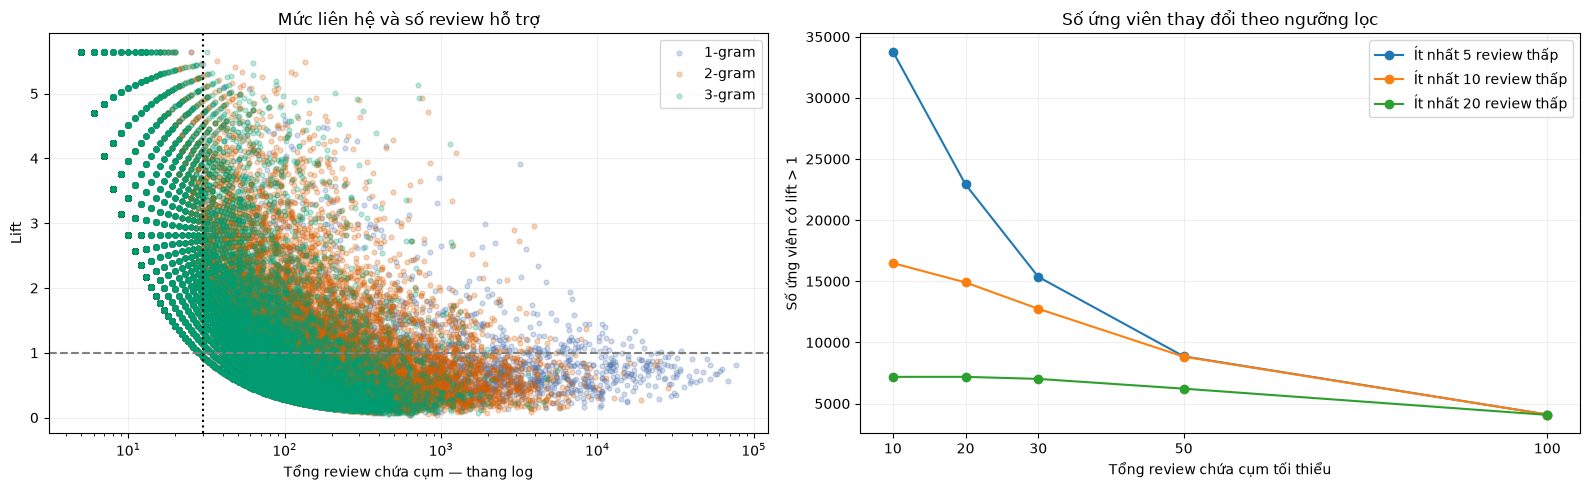

,Tổng review tối thiểu,Review thấp tối thiểu,Số ứng viên còn lại
0,10,5,33791
1,20,5,22916
2,30,5,15364
3,50,5,8864
4,100,5,4106
5,10,10,16491
6,20,10,14906
7,30,10,12753
8,50,10,8838
9,100,10,4106


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors = {1: "#4C72B0", 2: "#D55E00", 3: "#009E73"}

for n, color in colors.items():
    part = stats.loc[stats["ngram_size"].eq(n)]

    axes[0].scatter(
        part["support"],
        part["lift"],
        s=12,
        alpha=0.25,
        color=color,
        label=f"{n}-gram",
        rasterized=True,
    )

axes[0].set_xscale("log")
axes[0].axhline(1, color="gray", linestyle="--")
axes[0].axvline(MIN_SUPPORT, color="black", linestyle=":")
axes[0].set(
    title="Mức liên hệ và số review hỗ trợ",
    xlabel="Tổng review chứa cụm — thang log",
    ylabel="Lift",
)
axes[0].legend()

# So sánh các cấu hình; dùng lại stats, không cần đếm văn bản lại
support_thresholds = [10, 20, 30, 50, 100]
sensitivity_rows = []

for min_low in [5, 10, 20]:
    counts = []

    for min_total in support_thresholds:
        count = int((
            stats["support"].ge(min_total)
            & stats["low_support"].ge(min_low)
            & stats["lift"].gt(1)
        ).sum())

        counts.append(count)
        sensitivity_rows.append({
            "Tổng review tối thiểu": min_total,
            "Review thấp tối thiểu": min_low,
            "Số ứng viên còn lại": count,
        })

    axes[1].plot(
        support_thresholds,
        counts,
        marker="o",
        label=f"Ít nhất {min_low} review thấp",
    )

axes[1].set(
    title="Số ứng viên thay đổi theo ngưỡng lọc",
    xlabel="Tổng review chứa cụm tối thiểu",
    ylabel="Số ứng viên có lift > 1",
    xticks=support_thresholds,
)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

#### Insight từ độ nhạy: ngưỡng lọc là lựa chọn nghiên cứu có ảnh hưởng lớn, chưa phải “đúng” theo mặc định

**Quan sát.** Với baseline $p_0=19.415/109.674\approx17,70\%$, lift không vượt $1/p_0\approx5,65$ vì tỷ lệ tệ khi có cụm không thể vượt 1. Ở support ≥30, tăng số review tệ tối thiểu **5 →10 →20** làm số cụm còn **15.364 →12.753 →7.019**. Riêng 10 →20 giảm khoảng **44,96%** danh sách. Giữ yêu cầu ít nhất 10 review tệ và tăng support **30 →100** chỉ còn **4.106 cụm**, giảm **67,80%**.

**Insight về scatter.** Một phần các dải/giới hạn trên hình đến từ đại số và ngưỡng sinh từ điển. Chẳng hạn, cần ít nhất 5 review tệ nên với support $s$, lift có giới hạn dưới $5/(s p_0)$ trong tập ứng viên được sinh; điểm chạm 5,65 chỉ là cụm toàn review tệ trong mẫu. Vì vậy hình dạng không tự chứng minh cụm hiếm có ý nghĩa hơn hay trigram luôn tốt hơn unigram.

**Vai trò của kiểm tra độ nhạy.** Quy mô danh sách thay đổi đáng kể theo yêu cầu support, nên một “top list” luôn gắn với cấu hình đã chọn. Chọn ngưỡng lớn hơn làm danh sách gọn hơn và tăng số bằng chứng tối thiểu cho mỗi cụm, nhưng có thể loại dấu hiệu của nhóm bất mãn hiếm. Chọn ngưỡng thấp hơn giữ được phạm vi rộng hơn nhưng làm khối lượng đọc/nguy cơ kết quả ít support tăng lên.

**Quyết định trong pipeline.** Giữ (30,10) để bám cấu hình khảo sát hiện tại, chưa tuyên bố tối ưu. Thay vì siết ngưỡng để bảng đẹp hơn, bước 10 sẽ lấy một shortlist cân bằng giữa lift và độ phủ, rồi kiểm tra nội dung/shop. Như vậy, độ nhạy giúp nhận diện sự phụ thuộc vào tham số và quản lý phạm vi đọc, chưa thay thế đọc ngữ cảnh.

**Phản biện và kiểm chứng.** Bảng chỉ đo số cụm còn lại, chưa đo cụm nào đổi thứ hạng, chất lượng ý nghĩa hay hiệu quả trên validation. Các cụm xuất hiện dưới 5 review tệ đã bị loại từ đầu, nên chưa nằm trong thử nghiệm này. Muốn chốt ngưỡng cuối cần so độ ổn định danh sách/ngữ nghĩa và kiểm chứng ngoài discovery; dữ liệu hiện tại mới đủ để giữ một cấu hình vận hành minh bạch.

**Cơ sở:** bảng `sensitivity`, scatter và suy diễn đại số từ định nghĩa lift. Không so trực tiếp biên độ lift với một phiên bản dùng baseline khác để kết luận chất lượng tăng/giảm.


### 10. Chọn danh sách ngắn theo lift và độ phủ

Lấy hợp top 15 theo lift và top 15 theo độ phủ nhóm review tệ. Lift ưu tiên mức liên hệ; độ phủ ưu tiên khả năng tiếp cận nhiều review tệ. Tối đa 30 cụm để đọc, chưa phải bộ từ khóa tối ưu cho dự đoán.

**Quyết định do bước độ nhạy dẫn tới:** giữ ngưỡng chung để danh sách còn đủ rộng, nhưng không đọc tuần tự hàng chục nghìn cụm. Hai tiêu chí lấy mẫu có chủ đích giúp nhìn cả dấu hiệu rất đặc hiệu nhưng hiếm và dấu hiệu tiếp cận nhiều review tệ. Nếu hai top ít giao nhau, đó là bằng chứng cần tìm thêm cụm cân bằng ở giữa, thay vì cho rằng một tiêu chí tự đủ.


In [16]:
TOP_PER_CRITERION = 15

top_lift = candidates.nlargest(TOP_PER_CRITERION, "lift")
top_coverage = candidates.nlargest(
    TOP_PER_CRITERION, "prevalence_low"
)

lift_words = set(top_lift["keyword"])
coverage_words = set(top_coverage["keyword"])

shortlist = candidates.loc[
    candidates["keyword"].isin(lift_words | coverage_words)
].copy()

def selection_reason(keyword):
    reasons = []
    if keyword in lift_words:
        reasons.append("Lift cao")
    if keyword in coverage_words:
        reasons.append("Độ phủ cao")
    return " + ".join(reasons)

shortlist["selection_reason"] = shortlist["keyword"].map(
    selection_reason
)
shortlist = shortlist.sort_values(
    ["lift", "support"], ascending=False
).reset_index(drop=True)

view = shortlist[[
    "keyword", "selection_reason", "support",
    "low_support", "prevalence_low",
    "p_low_given_keyword", "lift"
]].copy()

for col in ["prevalence_low", "p_low_given_keyword"]:
    view[col] = view[col].map(lambda x: f"{x:.2%}")

view["lift"] = view["lift"].round(2)

display(view.rename(columns={
    "keyword": "Cụm ứng viên",
    "selection_reason": "Lý do chọn",
    "support": "Tổng review chứa cụm",
    "low_support": "Review thấp chứa cụm",
    "prevalence_low": "Độ phủ trong nhóm thấp",
    "p_low_given_keyword": "Tỷ lệ thấp khi có cụm",
    "lift": "Lift (lần)",
}))

,Cụm ứng viên,Lý do chọn,Tổng review chứa cụm,Review thấp chứa cụm,Độ phủ trong nhóm thấp,Tỷ lệ thấp khi có cụm,Lift (lần)
0,mùo vị tuyệt,Lift cao,32,32,0.16%,100.00%,5.65
1,mùo vị,Lift cao,37,36,0.19%,97.30%,5.50
2,mất dạy,Lift cao,135,131,0.67%,97.04%,5.48
3,làm ăn như,Lift cao,63,61,0.31%,96.83%,5.47
4,bêu,Lift cao,30,29,0.15%,96.67%,5.46
5,vô văn,Lift cao,48,46,0.24%,95.83%,5.41
6,lừa đảo,Lift cao,109,103,0.53%,94.50%,5.34
7,gian dối,Lift cao,53,50,0.26%,94.34%,5.33
8,bực vào người,Lift cao,34,32,0.16%,94.12%,5.32
9,tẩy chay,Lift cao,116,109,0.56%,93.97%,5.31


#### Insight từ shortlist: hai tiêu chí đang chọn hai cực, chưa chọn được lời giải cuối

**Quan sát.** Top 15 theo lift và top 15 theo độ phủ **không giao nhau**, nên hợp có **30 cụm**. Nhóm lift cao chứa nhiều biểu đạt hẹp như “mất dạy”, “lừa đảo” và các mảnh câu. Nhóm độ phủ cao gồm “lại” (**31,87%, lift 1,03**), “lần” (**23,46%, lift 1,01**), “ko” (**21,10%, lift 1,34**) và “thái” (**11,74%, lift 1,93**).

**Insight.** Một cụm phủ nhiều review tệ có thể đơn giản vì nó phổ biến trong mọi loại review: “lại” và “lần” có lift gần 1 nên chưa giúp phân biệt nhiều dù độ phủ lớn. Ngược lại, biểu đạt bất mãn mạnh có thể liên hệ rõ nhưng chỉ chạm một phần rất nhỏ nhóm tệ. Không có giao nhau cho thấy cách lấy hai top đang phơi ra sự đánh đổi đó; chưa chứng minh toàn bộ từ điển không có cụm cân bằng.

**Một đối chiếu cần đọc đúng.** “**Không**” có độ phủ **38,89%**, tỷ lệ tệ khi có từ **14,36%** và lift **0,81**, thấp hơn baseline 17,70%. Vì không đạt lift >1, từ này **không thuộc shortlist ứng viên liên hệ dương**; về sau nó được chọn riêng làm trường hợp đọc phủ định. Điều này cho thấy không thể gán sentiment âm cho một token chỉ vì nghĩa từ điển hoặc vì nó thường xuất hiện trong review tệ.

**Vai trò và quyết định tiếp theo.** Shortlist 30 cụm làm phạm vi đo text/shop và đọc mẫu khả thi hơn. Bước 11 sẽ hỏi số dòng hỗ trợ có tương ứng nhiều text/shop không; bước 13 tìm cụm 2–3 đơn vị như một cách giữ thêm ngữ cảnh, thay vì dừng ở “thái”, “tiền”, “quay”. Mục tiêu là hiểu tín hiệu, chưa xây bộ từ khóa dự đoán.

**Phản biện và kiểm tra lại.** Top 15 là giới hạn để đọc, không phải ngưỡng đã tối ưu. “Ko” và “không” có nghĩa phủ định gần nhau nhưng tỷ lệ thống kê khác nhau; chưa có phân tích cho phép khẳng định nguyên nhân là nhóm người viết, kiểu câu hay nhiễu. Không nên tự gộp/loại chúng chỉ từ bảng này. Cũng không cộng độ phủ 30 cụm, vì một review có thể chứa nhiều cụm và việc lấy hợp chưa đo tổng số review được bao phủ.

**Cơ sở:** bảng `shortlist` và đối chiếu dòng “không” trong `stats` của cùng lần chạy; đây là quy nạp có điều kiện về tính hữu ích của tiêu chí chọn cụm.


### 11. Kiểm tra nội dung và shop hỗ trợ từng cụm

Với shortlist, đo số text khác nhau, tỷ trọng text lớn nhất, số shop và tỷ trọng shop lớn nhất. Các số này tính trên toàn support của cụm trong discovery, gồm cả hai nhóm rating; tỷ trọng shop chỉ tính các review có shop xác định.

Nếu support chủ yếu đến từ một text hoặc shop, cần giới hạn khả năng khái quát. Đây là bước mô tả bằng chứng cho keyword trong pipeline cũ, không mở thêm quy trình khử trùng.

**Câu hỏi cần trả lời trước khi đọc nghĩa:** 32 review chứa một cụm là 32 cách diễn đạt khác nhau hay chỉ vài câu được lặp, và chúng có dồn vào một shop không? Hai tình huống này dẫn tới hai giới hạn khác nhau: lặp text có thể khuếch đại một cách nói, còn tập trung shop có thể làm liên hệ phản ánh một bối cảnh hẹp.

Các phép đo bổ sung bằng chứng cho việc ưu tiên đọc cụm, không thay đổi `df_clean` hay xóa lại comment. Điều này giữ bộ lọc đơn giản như đã thống nhất, đồng thời không bỏ qua ảnh hưởng của các text còn lặp tới kết luận keyword.


In [17]:
# Tạo ma trận chỉ cho tối đa 30 cụm đang kiểm tra
check_vectorizer = CountVectorizer(
    vocabulary=shortlist["keyword"].tolist(),
    ngram_range=(1, 3),
    token_pattern=TOKEN_PATTERN,
    lowercase=False,
    binary=True,
    dtype=np.int32,
)

# CSC thuận tiện để lấy các dòng chứa từng cụm
context_matrix = check_vectorizer.fit_transform(
    discovery["text_norm"]
).tocsc()

diagnostic_rows = []

for column, keyword in enumerate(shortlist["keyword"]):
    start = context_matrix.indptr[column]
    end = context_matrix.indptr[column + 1]
    row_indices = context_matrix.indices[start:end]

    matched = discovery.iloc[row_indices]
    text_counts = matched["text_norm"].value_counts()

    result = {
        "keyword": keyword,
        "unique_texts": matched["text_norm"].nunique(),
        "largest_text_share": text_counts.iloc[0] / len(matched),
        "known_shop_reviews": 0,
        "unique_shops": np.nan,
        "largest_shop_share": np.nan,
    }

    if "shop_id" in matched.columns:
        shop_ids = matched["shop_id"].astype("string").str.strip()

        known = (
            shop_ids.notna()
            & ~shop_ids.str.lower().isin(
                ["", "unknown", "none", "null", "nan"]
            )
        ).fillna(False)

        shop_counts = shop_ids.loc[known].value_counts()

        result["known_shop_reviews"] = int(known.sum())

        if not shop_counts.empty:
            result["unique_shops"] = len(shop_counts)
            result["largest_shop_share"] = (
                shop_counts.iloc[0] / shop_counts.sum()
            )

    diagnostic_rows.append(result)

diagnostics = shortlist.merge(
    pd.DataFrame(diagnostic_rows),
    on="keyword",
    validate="one_to_one",
)

diagnostic_view = diagnostics[[
    "keyword", "support", "unique_texts",
    "largest_text_share", "known_shop_reviews",
    "unique_shops", "largest_shop_share"
]].copy()

for col in ["largest_text_share", "largest_shop_share"]:
    diagnostic_view[col] = diagnostic_view[col].map(
        lambda x: f"{x:.1%}" if pd.notna(x) else "Chưa xác định"
    )

display(diagnostic_view.rename(columns={
    "keyword": "Cụm",
    "support": "Tổng review",
    "unique_texts": "Số nội dung khác nhau",
    "largest_text_share": "Tỷ trọng nội dung lặp nhiều nhất",
    "known_shop_reviews": "Review xác định được shop",
    "unique_shops": "Số shop",
    "largest_shop_share": "Tỷ trọng shop lớn nhất",
}))

,Cụm,Tổng review,Số nội dung khác nhau,Tỷ trọng nội dung lặp nhiều nhất,Review xác định được shop,Số shop,Tỷ trọng shop lớn nhất
0,mùo vị tuyệt,32,4,59.4%,32,13,12.5%
1,mùo vị,37,8,51.4%,37,14,16.2%
2,mất dạy,135,131,3.0%,135,78,23.0%
3,làm ăn như,63,61,3.2%,63,57,6.3%
4,bêu,30,23,13.3%,30,4,70.0%
5,vô văn,48,39,12.5%,48,24,27.1%
6,lừa đảo,109,105,1.8%,109,87,3.7%
7,gian dối,53,51,3.8%,53,42,11.3%
8,bực vào người,34,34,2.9%,34,33,5.9%
9,tẩy chay,116,90,9.5%,116,61,26.7%


#### Insight từ bằng chứng hỗ trợ: phải phân biệt lặp câu chữ với tập trung địa điểm

Một số cụm lift cao có cấu trúc bằng chứng rất khác nhau:

| Cụm | Review | Text khác nhau | Shop | Text lớn nhất | Shop lớn nhất |
| --- | --- | --- | --- | --- | --- |
| mùo vị tuyệt | 32 | 4 | 13 | 59.38% | 12.50% |
| mùo vị | 37 | 8 | 14 | 51.35% | 16.22% |
| mất dạy | 135 | 131 | 78 | 2.96% | 22.96% |
| làm ăn như | 63 | 61 | 57 | 3.17% | 6.35% |
| bêu | 30 | 23 | 4 | 13.33% | 70.00% |


**Insight 1 — phân tán shop chưa bảo đảm đa dạng nội dung.** “**Mùo vị tuyệt**” có **32 review ở 13 shop nhưng chỉ 4 text**, một text chiếm **59,38%** support. “Mùo vị” cũng có một text chiếm **51,35%**. Như vậy, việc xuất hiện ở nhiều shop chưa đủ để gọi đây là một biểu đạt được quan sát độc lập qua nhiều cách viết. Nhóm này cần đọc toàn văn để biết liên hệ phản ánh ý nghĩa hay vài câu lặp/đặc thù dữ liệu.

**Insight 2 — đa dạng text chưa bảo đảm phạm vi shop rộng.** “**Bêu**” có **23 text trong 30 review**, nhưng chỉ **4 shop** và shop lớn nhất chiếm **70%** support. Rủi ro chính ở đây không giống trường hợp trên: liên hệ có thể gắn với một vài bối cảnh địa điểm/sự việc. Đó là giả thuyết để ưu tiên đọc, chưa xác nhận các review cùng kể một sự kiện.

**Đối chiếu hữu ích.** “**Mất dạy**” có **131 text/135 review tại 78 shop**, text lớn nhất **2,96%**, shop lớn nhất **22,96%**. Bằng chứng phân tán hơn theo text so với “mùo vị tuyệt”, nhưng vẫn có tập trung shop đáng xem. “**Làm ăn như**” có **61 text/63 review, 57 shop**, shop lớn nhất **6,35%**; phân tán rộng hơn vẫn chưa làm một mảnh câu trở thành khái niệm trải nghiệm rõ ràng.

**Vai trò và quyết định cho bước sau.** Cần nhìn cả hai trục text/shop cùng với lift/độ phủ. Bước 12 đặt các chỉ số cạnh nhau để thấy cụm nào hẹp về bằng chứng; bước 14 sẽ đọc “mùo vị tuyệt” như một ca cần xác minh nghĩa và “mất dạy” như một biểu đạt bất mãn để đối chiếu. Không xóa thêm review chỉ vì mức tập trung cao, cũng chưa nâng cụm phân tán rộng thành kết luận nhân quả.

**Phản biện.** Các tỷ trọng tính trên **toàn support**, gồm cả nhóm ≤5 và >5, chưa riêng review tệ. Bảng mới đo shortlist, chưa có số tập trung của mọi cụm, chẳng hạn “thái độ” trong bảng 2–3 đơn vị sau đó. Nhiều text khác nhau vẫn có thể cùng người/sự kiện; text giống nhau vẫn có thể là các đánh giá riêng. Nếu cần phát biểu khái quát, phải đo lại theo nhóm đích và kiểm tra thời gian/shop chi phối; bước đó chưa được thực hiện ở đây.

**Cơ sở:** `diagnostics` ngay trên. Nhận xét tập trung là mô tả số đếm; diễn giải về cơ chế lặp/sự kiện là giả thuyết, chưa là kết quả xác minh nguồn.


### 12. Trực quan hóa độ phủ, lift và mức tập trung shop

Scatter đặt độ phủ nhóm tệ cạnh lift; kích thước điểm tăng theo `log1p(support)`. Biểu đồ phải chọn 15 cụm trong shortlist có tỷ trọng shop lớn nhất cao nhất. Đọc cả hai để cân bằng liên hệ, số review được giải thích và mức phụ thuộc vào shop.

**Vai trò của biểu đồ tổng hợp:** bảng trước cho biết từng chỉ số, còn hình giúp kiểm tra xem tiêu chí mạnh về liên hệ có đi cùng độ phủ lớn và bối cảnh phân tán không. Nếu những điểm lift cao đều nằm sát trái, cần chủ động tìm cụm phủ rộng hơn; nếu một cụm đồng thời tập trung mạnh vào một shop, cần giới hạn cách gọi nó là tín hiệu tổng quát.


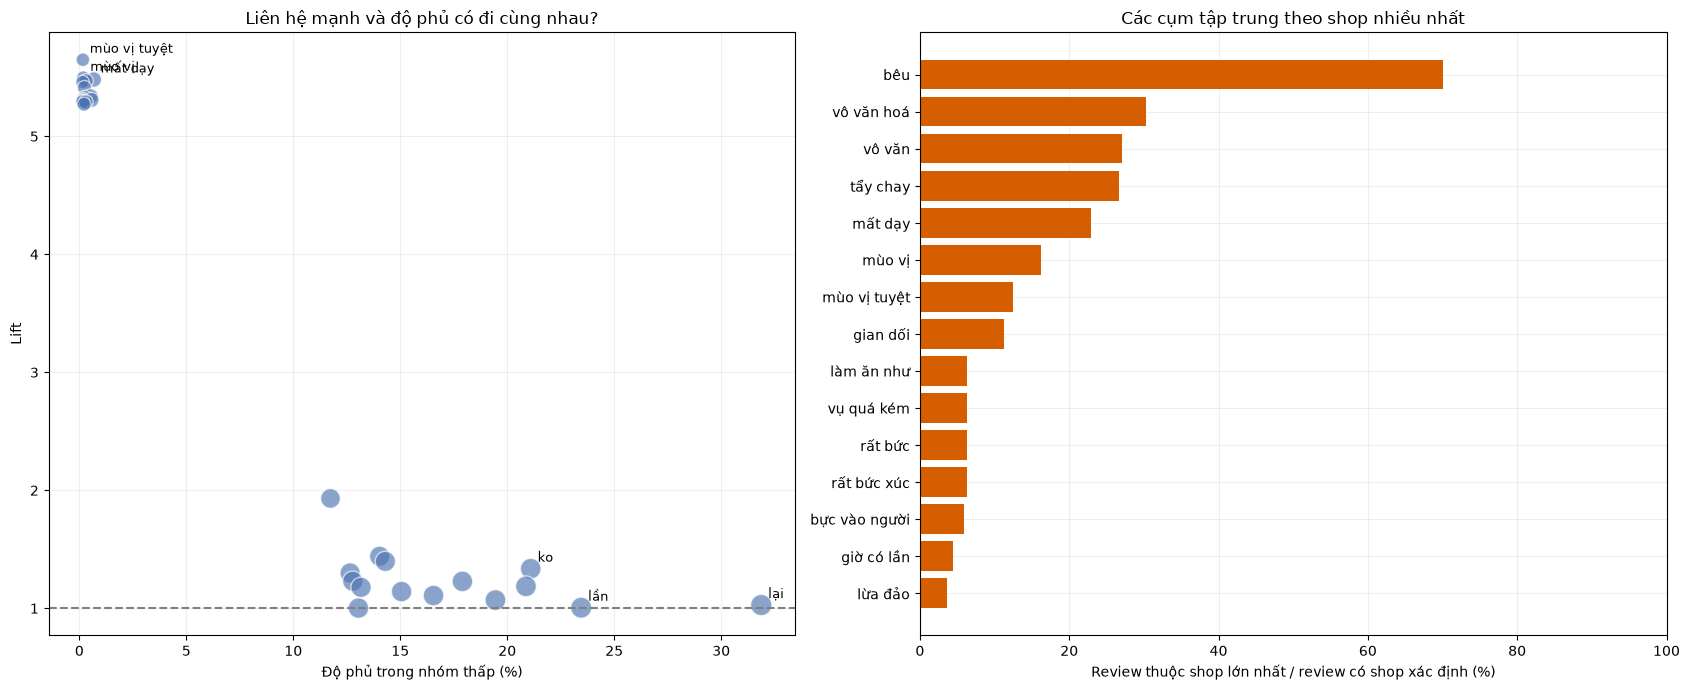

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# 1. Độ phủ và lift
axes[0].scatter(
    diagnostics["prevalence_low"] * 100,
    diagnostics["lift"],
    s=25 + 20 * np.log1p(diagnostics["support"]),
    alpha=0.65,
    color="#4C72B0",
    edgecolors="white",
)

labels = pd.concat([
    diagnostics.nlargest(3, "lift"),
    diagnostics.nlargest(3, "prevalence_low"),
]).drop_duplicates("keyword")

for _, row in labels.iterrows():
    axes[0].annotate(
        row["keyword"],
        (row["prevalence_low"] * 100, row["lift"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
    )

axes[0].axhline(1, color="gray", linestyle="--")
axes[0].set(
    title="Liên hệ mạnh và độ phủ có đi cùng nhau?",
    xlabel="Độ phủ trong nhóm thấp (%)",
    ylabel="Lift",
)

# 2. Mức tập trung theo shop
concentrated = (
    diagnostics.dropna(subset=["largest_shop_share"])
    .nlargest(15, "largest_shop_share")
    .sort_values("largest_shop_share")
)

if not concentrated.empty:
    axes[1].barh(
        concentrated["keyword"],
        concentrated["largest_shop_share"] * 100,
        color="#D55E00",
    )
    axes[1].set(
        title="Các cụm tập trung theo shop nhiều nhất",
        xlabel="Review thuộc shop lớn nhất / review có shop xác định (%)",
        xlim=(0, 100),
    )
else:
    axes[1].text(
        0.5, 0.5, "Không đủ thông tin shop",
        ha="center", va="center",
        transform=axes[1].transAxes,
    )

for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Insight từ biểu đồ tổng hợp: cần tìm cụm cân bằng hơn và kiểm tra nghĩa, thay vì chỉ lấy điểm cao nhất

**Quan sát.** Trong 30 cụm, lift dao động khoảng **1,00–5,65**, độ phủ nhóm tệ **0,15%–31,87%**. Các cụm top lift như “mùo vị tuyệt”/“mất dạy” nằm gần phía độ phủ thấp; các token như “lại” phủ rộng hơn nhưng lift sát nền. Biểu đồ shop nổi bật “**bêu**” với **70%** support ở một shop, trong khi các token rất phổ biến thường trải qua nhiều shop hơn.

**Insight.** Một điểm cao trên trục lift có thể là dấu hiệu đặc thù của ít review; một điểm xa bên phải có thể chỉ là từ quá chung. Phân tán shop cũng không tự giải quyết lặp text, như trường hợp “mùo vị tuyệt” đã thấy. Vì vậy không có một trục đơn lẻ đủ để ưu tiên keyword; cần phối hợp mức liên hệ, độ phủ, quy mô bằng chứng và ý nghĩa trong câu.

**Vai trò và quyết định dẫn sang phần 13.** Shortlist đang được chọn từ hai cực nên bước tiếp theo sẽ xét lại **cụm 2–3 đơn vị có lift ≥2**, xếp theo độ phủ. Đây là cách tìm thêm ứng viên giữ ngữ cảnh và vẫn liên hệ tương đối rõ, chẳng hạn mở từ “thái” sang “thái độ” thay vì chọn một token chung. Các cụm tập trung shop hoặc text vẫn được giữ trong danh sách đọc để hiểu hạn chế, chưa tự loại khỏi dữ liệu.

**Phản biện và kiểm chứng.** Hình chỉ vẽ 30 cụm được chọn có chủ đích; không thể suy rằng mọi ứng viên trong 63.882 cụm đều có cùng sự đánh đổi. Kích thước điểm tăng theo `log1p(support)`, không tỷ lệ tuyến tính với số review, nên không dùng diện tích để ước lượng trực tiếp số bằng chứng. Tỷ trọng shop lớn chưa chứng minh quan hệ nhân quả do shop hoặc sự kiện; nếu dùng kết quả cho shop mới, cần kiểm chứng ngoài những địa điểm đang chi phối.

**Cơ sở:** scatter và bar chart từ `diagnostics`; quyết định xét cụm nhiều đơn vị là hướng EDA thực sự được thực hiện ngay sau, chưa phải xác nhận chúng sẽ tốt hơn.


### 13. Ưu tiên cụm 2–3 đơn vị có ý nghĩa dễ đọc

Giữ cụm 2–3 đơn vị trong `candidates` có lift ≥2 rồi xếp theo độ phủ nhóm tệ, như pipeline cũ. Một cụm nhiều token có thể giữ ngữ cảnh tốt hơn unigram nhưng vẫn có thể là mảnh câu.

Chọn thêm các vai trò để đọc: cụm lift cao nhất, biểu đạt bất mãn, từ phủ định và cụm nhiều đơn vị phủ rộng. Chỉ chọn cụm có trong từ điển; không mặc định chúng là nguyên nhân gây review tệ.

**Vì sao điều kiện lift ≥2 vẫn cần độ phủ?** Điều kiện đó yêu cầu tỷ lệ review tệ khi có cụm ít nhất gấp đôi baseline discovery, nhưng vẫn có thể giữ cụm rất hiếm. Xếp theo độ phủ sau điều kiện liên hệ giúp ưu tiên những cụm chạm nhiều review tệ hơn, thay vì tiếp tục chỉ nhìn cực đại lift.

Đây là thiết kế khảo sát giữ từ pipeline cũ, không phải chứng minh ngưỡng 2 tối ưu cho nhãn ≤5. Nếu kết quả chủ yếu là mảnh câu, bước đọc ngữ cảnh sẽ quyết định cần gộp nghĩa, mở rộng cụm hay chỉ ghi nhận chúng như biểu đạt, thay vì gọi luôn là nguyên nhân trải nghiệm.


In [19]:
phrase_candidates = candidates.loc[
    candidates["ngram_size"].ge(2)
    & candidates["lift"].ge(2)
].sort_values(
    ["prevalence_low", "lift"],
    ascending=[False, False]
).copy()

phrase_view = phrase_candidates.head(15)[[
    "keyword", "support", "low_support",
    "prevalence_low", "p_low_given_keyword", "lift"
]].copy()

for col in ["prevalence_low", "p_low_given_keyword"]:
    phrase_view[col] = phrase_view[col].map(
        lambda value: f"{value:.2%}"
    )

phrase_view["lift"] = phrase_view["lift"].round(2)

display(phrase_view.rename(columns={
    "keyword": "Cụm ứng viên",
    "support": "Tổng review chứa cụm",
    "low_support": "Review thấp chứa cụm",
    "prevalence_low": "Độ phủ trong nhóm thấp",
    "p_low_given_keyword": "Tỷ lệ thấp khi có cụm",
    "lift": "Lift (lần)",
}))

# Chọn các trường hợp có vai trò khác nhau để đọc thử
inspection_targets = [
    (candidates.iloc[0]["keyword"], "Cụm có lift cao nhất"),
    ("mất dạy", "Cụm thể hiện bất mãn mạnh"),
    ("không", "Từ cần đọc cùng ngữ cảnh phủ định"),
]

if not phrase_candidates.empty:
    inspection_targets.append((
        phrase_candidates.iloc[0]["keyword"],
        "Cụm nhiều đơn vị có độ phủ cao"
    ))

# Chỉ giữ cụm có trong từ điển, tránh trùng lựa chọn
inspection_keywords = []
inspection_reasons = {}

for keyword, reason in inspection_targets:
    if (
        keyword in vectorizer.vocabulary_
        and keyword not in inspection_keywords
    ):
        inspection_keywords.append(keyword)
        inspection_reasons[keyword] = reason

display(pd.DataFrame({
    "Cụm sẽ đọc": inspection_keywords,
    "Lý do": [
        inspection_reasons[word]
        for word in inspection_keywords
    ],
}))

,Cụm ứng viên,Tổng review chứa cụm,Review thấp chứa cụm,Độ phủ trong nhóm thấp,Tỷ lệ thấp khi có cụm,Lift (lần)
44299,thái độ,3917,2053,10.57%,52.41%,2.96
46149,thất vọng,3160,1523,7.84%,48.20%,2.72
2017,bao giờ,2922,1501,7.73%,51.37%,2.90
49771,tính tiền,2627,988,5.09%,37.61%,2.12
19919,không bao,1243,899,4.63%,72.33%,4.09
19921,không bao giờ,1141,852,4.39%,74.67%,4.22
19448,khách hàng,1916,804,4.14%,41.96%,2.37
19790,khó chịu,1864,709,3.65%,38.04%,2.15
43195,sẽ không,1577,703,3.62%,44.58%,2.52
48317,trong khi,1175,695,3.58%,59.15%,3.34


,Cụm sẽ đọc,Lý do
0,mùo vị tuyệt,Cụm có lift cao nhất
1,mất dạy,Cụm thể hiện bất mãn mạnh
2,không,Từ cần đọc cùng ngữ cảnh phủ định
3,thái độ,Cụm nhiều đơn vị có độ phủ cao


#### Insight từ cụm nhiều đơn vị: bắt đầu phân biệt khía cạnh trải nghiệm, cảm xúc và ý định

**Quan sát.** Có **3.871 cụm 2–3 đơn vị** đáp ứng điều kiện hiện tại. Các cụm đầu theo độ phủ gồm:

| Cụm | Support | Review tệ | Độ phủ nhóm tệ | Tỷ lệ tệ khi có cụm | Lift |
| --- | --- | --- | --- | --- | --- |
| thái độ | 3.917 | 2.053 | 10.57% | 52.41% | 2.96 |
| thất vọng | 3.160 | 1.523 | 7.84% | 48.20% | 2.72 |
| bao giờ | 2.922 | 1.501 | 7.73% | 51.37% | 2.90 |
| tính tiền | 2.627 | 988 | 5.09% | 37.61% | 2.12 |
| không bao | 1.243 | 899 | 4.63% | 72.33% | 4.09 |


**Insight về ưu tiên.** “**Thái độ**” có **2.053/3.917 review tệ (52,41%)**, độ phủ **10,57%**, lift **2,96**. So với unigram “thái” ở shortlist (**11,74%**, lift **1,93**), cụm hai đơn vị giảm nhẹ phạm vi nhưng tăng mức liên hệ và giữ nghĩa dễ đọc hơn. So với “mất dạy” (**0,67%**, lift **5,48**), “thái độ” phủ phần lớn hơn của nhóm đích dù ít đặc hiệu hơn. Vì vậy đây là ứng viên phù hợp để đọc về khía cạnh tương tác/phục vụ, chưa phải kết luận nguyên nhân quan trọng nhất.

**Insight về loại thông tin.** “**Thất vọng**” phủ **7,84%**, lift **2,72**, nghiêng về biểu đạt phản ứng; “**tính tiền**” phủ **5,09%**, lift **2,12**, gợi chủ đề thanh toán cần đọc cách mô tả. “**Bao giờ**” hay “**không bao**” có thể là mảnh của một ý định dài hơn. Bảng còn có “**không bao giờ**” với **1.141 review**, tỷ lệ tệ **74,67%**, lift **4,22**: giữ thêm đơn vị có thể giúp đọc câu, nhưng vẫn phải xác định khách nói không quay lại, chưa từng trải nghiệm hay nghĩa khác.

**Vai trò và quyết định sang phần 14.** Các kết quả cho phép thiết kế mẫu đọc có đối chiếu: một ca top lift có text lặp (“mùo vị tuyệt”), một biểu đạt bất mãn (“mất dạy”), một token phủ định (“không”) và một khía cạnh phủ rộng hơn (“thái độ”). Mỗi ca trả lời một câu hỏi khác nhau về tính hợp lệ của keyword; không chỉ lấy các ví dụ chê để xác nhận giả thuyết phục vụ.

**Phản biện và kiểm chứng.** Bảng 2–3 đơn vị không tự phân biệt nguyên nhân, cảm xúc và hệ quả/ý định; cần gán nghĩa trong toàn câu. Những cụm chồng lấp như “không bao”, “bao giờ” và “không bao giờ” có thể cùng nằm trong một review nên không cộng support/độ phủ hoặc xem là ba bằng chứng độc lập. Chưa đo mức tập trung riêng của mọi cụm ở bảng này và chưa dùng validation; thứ hạng chỉ là ưu tiên đọc trong discovery.

**Cơ sở:** `phrase_candidates`, bảng top 15 nhiều đơn vị, cùng các đối chiếu ở `shortlist`/`candidates` đã hiển thị. Diễn giải các nhóm ý nghĩa là giả thuyết có điều kiện cần đối chiếu bằng mẫu tiếp theo.


### 14. Đọc ngữ cảnh và kết luận EDA sơ bộ

Với các cụm vừa chọn, lấy tối đa hai text khác nhau thuộc nhóm **rating ≤5** và một text thuộc nhóm **rating >5**, `random_state=42`. Bản xem trước lấy vùng quanh cụm; giữ comment đầy đủ trong `inspection_examples` để đọc lại.

Đây là mẫu có chủ đích theo cụm và nhãn, không dùng tỷ lệ 2:1 để ước lượng xác suất. Kiểm tra đối tượng được nhận xét, phủ định, từ nhiều nghĩa và cả trường hợp có cùng cụm nhưng rating >5 trước khi kết luận.

**Câu hỏi để quyết định sau khi đọc:** (1) Cụm top lift có thực sự nói điều tiêu cực không? (2) Từ bất mãn mạnh có luôn đi cùng rating ≤5 không? (3) Phủ định tác động vào phần nào của câu? (4) “Thái độ” là lời chê hay chỉ là tên khía cạnh có thể được khen? Nếu trả lời khác với giả định khi nhìn bảng, cần điều chỉnh diễn giải và hướng kiểm chứng, không tự thay rating hoặc xóa review để giữ bảng top như mong đợi.


In [20]:
inspection_vectorizer = CountVectorizer(
    vocabulary=inspection_keywords,
    ngram_range=(1, 3),
    token_pattern=TOKEN_PATTERN,
    lowercase=False,
    binary=True,
    dtype=np.int32,
)

inspection_matrix = inspection_vectorizer.fit_transform(
    discovery["text_norm"]
).tocsc()


def context_excerpt(text, keyword, radius=230):
    # Cho phép dấu câu giữa các đơn vị, giống cách n-gram bỏ qua dấu câu
    pattern = (
        r"(?<!\w)"
        + r"\W+".join(re.escape(token) for token in keyword.split())
        + r"(?!\w)"
    )

    match = re.search(pattern, text)

    if match is None:
        return text[:2 * radius]

    left = max(0, match.start() - radius)
    right = min(len(text), match.end() + radius)

    return (
        ("..." if left > 0 else "")
        + text[left:right]
        + ("..." if right < len(text) else "")
    )


example_rows = []

for column, keyword in enumerate(inspection_keywords):
    left = inspection_matrix.indptr[column]
    right = inspection_matrix.indptr[column + 1]
    matched_indices = inspection_matrix.indices[left:right]

    matched = discovery.iloc[matched_indices]

    print("\n" + "=" * 70)
    print("CỤM:", keyword)
    print("LÝ DO ĐỌC:", inspection_reasons[keyword])
    print("Tổng review chứa cụm trong tập khám phá:", len(matched))

    for is_low, sample_size in [(True, 2), (False, 1)]:
        pool = (
            matched.loc[matched["is_low"].eq(is_low)]
            .drop_duplicates("text_norm")
        )

        if pool.empty:
            continue

        chosen = pool.sample(
            n=min(sample_size, len(pool)),
            random_state=42,
        )

        for _, row in chosen.iterrows():
            group_name = "Điểm thấp" if is_low else "Nhóm còn lại"
            excerpt = context_excerpt(row["text_norm"], keyword)

            print(f"\n[{group_name}] Rating: {row['rating_num']}")
            print("Review ID:", row.get("review_id", "Không có"))
            print("Shop:", row.get("shop_id", "Không có"))
            print("Ngữ cảnh:", excerpt)

            example_rows.append({
                "keyword": keyword,
                "group": group_name,
                "rating": row["rating_num"],
                "review_id": row.get("review_id"),
                "shop_id": row.get("shop_id"),
                "context_excerpt": excerpt,
                "comment_text": row["comment_text"],
            })

inspection_examples = pd.DataFrame(example_rows)


CỤM: mùo vị tuyệt
LÝ DO ĐỌC: Cụm có lift cao nhất
Tổng review chứa cụm trong tập khám phá: 32

[Điểm thấp] Rating: 5.0
Review ID: 53369
Shop: mi-y-double-b-to-hien-thanh
Ngữ cảnh: mùo vị tuyệt vời mềm và ngọt

[Điểm thấp] Rating: 5.0
Review ID: 99574
Shop: com-tam-suon-que-nuong-ngo-gia-tu
Ngữ cảnh: mùo vị tuyệt bời mềm và ngọt

CỤM: mất dạy
LÝ DO ĐỌC: Cụm thể hiện bất mãn mạnh
Tổng review chứa cụm trong tập khám phá: 135

[Điểm thấp] Rating: 1.0
Review ID: 30085
Shop: banh-bo-thot-not-nguyen-son-le-tu-tai
Ngữ cảnh: giao hàng nước dừa chua, bắt khách hàng ăn thử, trong khi ngửi đã thấy chua (dù kh có ăn thử rồi mới đổi trả) ngta đổi trả lại thì đem hình ảnh gia đình ngta lên fb bêu rếu chửi rủa cmt nói chuyện mất dạy, không biết mình sai đừng ai ăn của nó, cho nó dẹp tiệm đi

[Điểm thấp] Rating: 1.0
Review ID: 99851
Shop: ga-ran-burger-lotteria-nha-trang-thong-nhat
Ngữ cảnh: ...hấy phần bắp cải kèm theo là 10k thì mình có chọn mua thêm. thì bạn nhân viên đứng cashier tên hiền trả lời 

#### Insight từ ngữ cảnh: số liệu theo rating và ý nghĩa ngôn ngữ phải được nối lại trước khi chọn fatal keyword

Các mẫu đối chiếu từ cell vừa chạy:

| Cụm | Nhóm | Rating | Đoạn xem trước |
| --- | --- | --- | --- |
| mùo vị tuyệt | Điểm thấp | 5.00 | mùo vị tuyệt vời mềm và ngọt… |
| mất dạy | Điểm thấp | 1.00 | giao hàng nước dừa chua, bắt khách hàng ăn thử, trong khi ngửi đã thấy chua (dù kh có ăn thử rồi mới đổi trả) ngta đổi trả lại thì đem hình ảnh g… |
| mất dạy | Nhóm còn lại | 7.60 | ...ngon hơn các chuỗi như hut, the pizza company, al fresco nhiều. view đẹp, thoáng mát, quán lịch sự, sạch sẽ. giá cả mắc nhưng tương ứng với ch… |
| không | Điểm thấp | 1.00 | đồ ăn ngon, nhiều, giá cũng không gọi là rẻ, giá tạm được thôi. nhưng mình nghĩ chủ quán nên học lại cách phục vụ thì sẽ tốt hơn. điển hình là ai… |
| không | Nhóm còn lại | 7.80 | ...ai hảo rồi là đâm ghiền luôn, đặc biệt là những quán bán chất lượng nhiư vầy. quán đói diên xéo bánh mì nướng muối ớt cô tám, bán 1 tô khá nhi… |
| thái độ | Điểm thấp | 5.00 | sinh tố thì uống ngon, mà thái độ phục vụ thì như kiểu k nhanh đuổi khách để lấy bàn cho người khác ngồi. tệ hơn là gửi xe 15k/chiếc với cái cách… |
| thái độ | Nhóm còn lại | 9.80 | quán ăn khá ngon, giá cả hợp lý, ăn tại quán thái độ nhân viên phục vụ nhiệt tình đồ ăn mang về cũng được gói khá đầy đủ nước châm và dưa vẫn là … |


**1. Top lift có thể phản ánh đặc thù nhãn/text, chưa phải nghĩa tiêu cực.** Hai mẫu “**mùo vị tuyệt**” đều rating **5** và có lời khen “mềm và ngọt”. Kết hợp với **32/32 review ≤5 nhưng chỉ 4 text** ở phần 11, đây là lý do chưa chọn cụm này làm từ khóa tiêu cực dù lift đứng đầu. Liên hệ với nhãn được tính đúng theo định nghĩa ≤5; vấn đề nằm ở việc suy từ nhãn theo điểm sang sentiment. Chưa biết nguyên nhân là cách người dùng chấm điểm, quy ước nguồn hay xử lý dữ liệu, nên không tự sửa rating/xóa thêm.

**2. Một khía cạnh xấu không quyết định toàn bộ điểm đánh giá.** Với “**mất dạy**”, mẫu rating **7,6** vẫn chê nhân viên nhưng khen món ăn, không gian và chấp nhận quay lại vì đồ ăn. Điều này giải thích vì sao một biểu đạt bất mãn mạnh vẫn có thể xuất hiện ở nhóm >5. Kết luận phù hợp là review có thể tổng hợp nhiều khía cạnh, không phải các dòng đối chứng đều tích cực hoặc mọi lời chê đều buộc rating ≤5.

**3. Phải giữ phạm vi của phủ định.** Trong mẫu rating **7,8**, “**không**” đi với “không tanh”, tạo đánh giá thuận lợi về món ăn. Các mẫu rating 1 lại dùng từ trong câu phàn nàn về phục vụ/chi phí. Kết quả này phù hợp với việc unigram “không” có lift **0,81**, và cho thấy xóa phủ định hoặc gán mọi câu chứa nó là tiêu cực đều làm mất nghĩa. Hướng xử lý là đọc cụm/câu và đối tượng được nhận xét.

**4. “Thái độ” là tên khía cạnh, còn mức đánh giá nằm ở cách mô tả.** Mẫu rating **5** khen sinh tố nhưng chê cách phục vụ/gửi xe; mẫu rating **1** chê cách nhận đơn; mẫu **9,8** khen nhân viên nhiệt tình. Với support và độ phủ đã đo, tương tác/phục vụ là hướng khảo sát đáng ưu tiên, nhưng một nhãn khía cạnh chưa phải một từ tiêu cực cố hữu.

**Quyết định sau bước đọc.** Kết luận EDA sẽ giữ “thái độ” như ứng viên khía cạnh cần khảo sát, “mất dạy” như biểu đạt bất mãn hẹp, “không” như trường hợp phải đọc phủ định, và “mùo vị tuyệt” như ca cần kiểm tra nhãn/lặp text. Chưa chốt một bộ từ khóa gây review tệ hoặc dùng rating thay nhãn sentiment. Các bước kiểm chứng sau nên tách việc kiểm tra liên hệ theo điểm khỏi việc gán nghĩa/khía cạnh trong văn bản.

**Phản biện và cách kiểm tra lại.** Mỗi cụm chỉ có tối đa hai text nhóm ≤5 và một text nhóm >5, còn “mùo vị tuyệt” không có mẫu >5 để so trong discovery. Cùng một review có thể được chọn cho nhiều cụm; excerpt có thể cắt mất đầu/cuối câu. Vì vậy không suy tỷ lệ sentiment hay cơ chế nhân quả từ mẫu này. Cần đọc toàn văn trong `inspection_examples`, lấy thêm mẫu phân tầng rating/shop và đối chiếu nguồn cho các ca nhãn–nội dung không tương ứng. Các lời phàn nàn cũng là nội dung người dùng kể, chưa xác nhận sự việc thực tế đã xảy ra như mô tả.

**Cơ sở:** output mẫu rating/ID/ngữ cảnh của `inspection_examples`, kết hợp bảng liên hệ và mức tập trung trước đó. Đây là quy nạp có điều kiện và kiểm tra phản ví dụ, chưa là gán nhãn chuẩn toàn tập.


### Kết luận EDA sơ bộ — kết thúc phần 14

**Câu trả lời ở mức bằng chứng hiện tại:** với nhãn **review tệ = rating ≤5**, dữ liệu cho phép ưu tiên một số biểu đạt/khía cạnh liên hệ với điểm, nhưng chưa cho phép gọi một chuỗi là nguyên nhân hay từ khóa “quyết định” review tệ. Đóng góp chính của EDA là tách **liên hệ theo rating**, **quy mô bằng chứng**, **mức tập trung** và **nghĩa trong ngữ cảnh**, rồi dùng các mặt đó để quyết định nên kiểm chứng gì tiếp.

#### Từ mỗi bước EDA đến quyết định phân tích

| Bằng chứng đã quan sát | Insight | Quyết định trong pipeline / bước tiếp |
| --- | --- | --- |
| 138.131 dòng qua kiểm tra text/rating hình thức; vẫn có 40 điểm 0 và 17.619 dòng thuộc text lặp | Rủi ro chính chuyển sang ý nghĩa nhãn và mức lặp nội dung | Lọc bằng khóa gọn, giữ dữ liệu gốc; đọc mẫu nhãn và theo dõi text/shop |
| Bộ lọc bỏ 437 dòng, còn 137.694; vẫn giữ 126.236 text khác nhau | Giảm đếm lặp theo khóa mà chưa loại một cách diễn đạt khỏi tập | Dùng df_clean cho downstream, không xóa mọi text lặp |
| 32.981.545 lượt 1–3 gram; độ dài có đuôi phải; 167 dòng không token | Số dòng chưa đủ mô tả khối lượng và giới hạn đặc trưng | Giữ bài dài, dùng binary/sparse/theo lô; loại 0 token riêng ở bước n-gram |
| 12.784 review có 4 < rating ≤5, chiếm 52,51% nhóm tệ | Ngưỡng mới nghiên cứu nhóm rộng, không chỉ bất mãn cực đoan | Tính lại toàn bộ baseline/support/lift; không mặc định nhãn điểm là sentiment |
| Discovery có 109.674 review, 19.415 tệ; baseline 17,70%; không giao text với validation | Có tập khám phá nhất quán, vẫn cần kiểm chứng ngoài dữ liệu chọn cụm | Sinh ứng viên chỉ trên discovery; giữ validation chưa dùng |
| 63.882 ứng viên, 12.753 cụm qua ngưỡng; số cụm nhạy theo support | Top list phụ thuộc cấu hình và có nhiều cụm chồng lấp | Giữ cấu hình khảo sát, lấy shortlist hai tiêu chí rồi đọc bằng chứng |
| Top lift có độ phủ hẹp; “mùo vị tuyệt” chỉ 4 text, “bêu” tập trung 70% ở một shop | Support chưa đồng nghĩa bằng chứng độc lập/khái quát | Xem text và shop đồng thời; chưa chốt theo lift đơn lẻ |
| Mẫu “mùo vị tuyệt” rating 5 có lời khen; “mất dạy” vẫn có mẫu 7,6; “thái độ” có cả khen/chê | Ngôn ngữ và rating liên hệ nhưng không đồng nhất | Tách khía cạnh, cảm xúc, ý định; kiểm tra lại nhãn và đọc đủ câu |

#### Những hướng nội dung có cơ sở để ưu tiên

“**Thái độ**” là hướng khảo sát tương tác/phục vụ đáng đọc trước: **2.053/3.917 review ≤5**, độ phủ **10,57%**, lift **2,96**; mẫu có cả chê phục vụ ở điểm 1/5 và khen nhân viên ở điểm 9,8. Điều này hỗ trợ tìm hiểu **cách phục vụ được mô tả**, chưa chứng minh đây là nguyên nhân quan trọng nhất của mọi review tệ. “**Thất vọng**” phủ **7,84%**, lift **2,72**, phù hợp như biểu đạt phản ứng để truy tìm nguyên nhân trong câu; “**tính tiền**” phủ **5,09%**, lift **2,12**, gợi khía cạnh thanh toán cần khảo sát thêm.

“**Mất dạy**” có tỷ lệ nhóm tệ cao (**131/135, lift 5,48**) nhưng độ phủ chỉ **0,67%**: hữu ích cho một nhóm bất mãn hẹp, chưa đại diện phần lớn review tệ. “**Bao giờ**”/“**không bao giờ**” cần đọc đủ câu để phân biệt ý định quay lại với nghĩa khác. Với “**mùo vị tuyệt**”, chưa đưa vào một bộ từ khóa tiêu cực: lift cao và 32/32 review ≤5 không vượt qua được phản ví dụ là các mẫu dùng lời khen. Đây là phát hiện về giới hạn diễn giải, không phải kết quả cần sửa dữ liệu để loại bỏ.

#### Hướng giải quyết tiếp theo, theo thứ tự ưu tiên

1. **Kiểm tra nhãn và ngữ nghĩa ở các ca có mâu thuẫn trước khi xây giải pháp.** Giữ đúng ngưỡng ≤5 hiện tại nhưng truy nguyên rating 0 và các mẫu rating 5 có lời khen; lấy thêm mẫu trong các dải điểm để xem giới hạn này rộng tới đâu. Không tự đổi điểm theo cảm xúc.
2. **Chuyển từ chuỗi n-gram sang khía cạnh/biểu đạt có nghĩa.** Gán nhãn thủ công trên discovery về đối tượng, khía cạnh, phủ định, cảm xúc và ý định; gom các mảnh chồng lấp khi có đủ ngữ cảnh. Mục tiêu là phân biệt vấn đề trải nghiệm với cách bộc lộ bất mãn hoặc ý định sau trải nghiệm.
3. **Kiểm tra độ nhạy của bằng chứng trước khi chốt shortlist.** So kết quả khi giới hạn đóng góp text lặp, bỏ shop/text chi phối và mở rộng bảng tập trung sang các cụm như “thái độ”. Đây là các phép kiểm chứng cần làm, chưa có kết quả trong notebook hiện tại.
4. **Chốt quy tắc trên discovery rồi kiểm chứng trên validation.** Dùng từ điển/tiêu chí cố định, tính baseline riêng trên validation và xem liên hệ/độ phủ có lặp lại không. Nếu dùng validation để chỉnh tiếp nhiều lần, cần một tập đánh giá cuối khác. Phần này chưa được chạy nên không công bố hiệu quả dự đoán.

#### Vòng phản biện trước khi nâng kết luận

Khóa lọc chỉ là quy ước EDA có thể hoàn tác, không xác nhận mọi dòng bị loại là lỗi nguồn. `df_raw`, `df_clean`, `dedup_removed` và báo cáo trước/sau là nơi đối chiếu. Bộ lọc giữ các review cùng text ở ngữ cảnh khác, nên support vẫn có thể phụ thuộc nội dung lặp; kiểm tra bằng chứng cần đi cùng kết luận, không thể coi 437 dòng bị bỏ là đã giải quyết mọi sự phụ thuộc.

Nhãn ≤5 gồm **40 review rating 0** và nhiều review ở khoảng trên 4 đến 5. Quy mô nhóm 0 nhỏ không bảo đảm tác động tới từng cụm hiếm nhỏ; cần phân tích độ nhạy thay vì khẳng định vô hại. Rating tổng thể có thể tổng hợp nhiều khía cạnh, nên nhóm >5 không đồng nghĩa sentiment tích cực ở mọi câu. Các mẫu ngữ cảnh là mẫu có chủ đích, không ước lượng được tỷ lệ ngữ nghĩa toàn tập.

Chia theo text hạn chế rò rỉ nguyên văn nhưng chưa tách người/shop/sự kiện. Nhiều n-gram chồng lấp không tạo bằng chứng độc lập, và độ phủ của chúng không được cộng thành tỷ lệ giải thích toàn bộ nhóm tệ. Chưa kiểm định nhiều cụm, chưa định lượng bất định và chưa có kết quả validation; do đó kết luận dừng ở ưu tiên hướng khảo sát. Thử nghiệm sentiment phần 15–18 chỉ là công cụ hỗ trợ đọc sau này, không tự xác nhận nguyên nhân hoặc thay thế nhãn chuẩn.

**Nguồn và quy tắc suy luận:** mọi số liệu lấy từ output phần 1–14 của lần chạy hiện tại, các tỷ trọng bổ sung được suy diễn từ số đếm đã nêu. Diễn giải dùng quy nạp có điều kiện và kiểm tra phản ví dụ; chưa xác định quan hệ nhân quả. Bảng tổng hợp trên cũng phân biệt quyết định đã có trong pipeline với các kiểm chứng được đề xuất cho bước tiếp theo.


## Phần 15 trở đi — hướng phân tích tiếp theo

Giữ các cell thử nghiệm sentiment bên dưới để tiếp tục sau. Đây là bước hỗ trợ đọc ngữ cảnh, tách khỏi kết luận EDA sơ bộ ở cuối phần 14. Các cell dự đoán chưa có output đã lưu; chưa có kết quả sentiment để diễn giải hoặc đánh giá độ chính xác. Nội dung và code phần 15–18 được giữ nguyên.


### 15.Thử baseline phân loại sentiment

Dùng model có sẵn để dự đoán sentiment của các đoạn ngữ cảnh đã lấy mẫu.

Chưa train hoặc fine-tune model.
Chưa dùng rating làm nhãn sentiment chuẩn.

Cài thư viện trong đúng môi trường kernel của notebook:
- torch: chạy model.
- transformers: tải tokenizer và model.
- underthesea: tách từ tiếng Việt.

In [ ]:
%pip install torch transformers underthesea

### 16.Chuẩn bị các đoạn văn cho model

Dùng context_excerpt từ Cell 14 để thử trước trên một số đoạn ngắn.
Đây là đoạn xung quanh keyword, có thể chưa chứa toàn bộ ý của review.

Tách từ tiếng Việt, ví dụ “thái độ” có thể thành “thái_độ”.
Giữ nguyên các từ phủ định.

Kiểm tra độ dài bằng tokenizer của model.
Những đoạn vượt 256 token được đánh dấu và tạm để riêng,
không tự cắt mất phần cuối để tránh hiểu sai ngữ cảnh.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from underthesea import word_tokenize

MODEL_NAME = "wonrax/phobert-base-vietnamese-sentiment"
MAX_TOKENS = 256

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

sentiment_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False,
)
sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
).to(device)

sentiment_model.eval()

pilot = inspection_examples.copy().reset_index(drop=True)
pilot.insert(0, "example_id", np.arange(1, len(pilot) + 1))

pilot["model_text"] = pilot["context_excerpt"].map(
    lambda text: word_tokenize(str(text), format="text")
)

pilot["model_tokens"] = pilot["model_text"].map(
    lambda text: len(
        sentiment_tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False,
        )
    )
)

pilot["can_predict"] = pilot["model_tokens"].le(MAX_TOKENS)

print("Thiết bị:", device)
print("Số đoạn thử:", len(pilot))
print("Đủ điều kiện độ dài:", int(pilot["can_predict"].sum()))
print("Tạm để riêng vì quá dài:", int((~pilot["can_predict"]).sum()))

display(pilot[[
    "example_id", "keyword", "model_tokens", "can_predict"
]])

### 17.Dự đoán sentiment của đoạn ngữ cảnh

Model trả điểm softmax cho:
- NEG: tiêu cực.
- POS: tích cực.
- NEU: trung lập.

Nhãn dự đoán là lớp có điểm cao nhất.
Điểm softmax không phải bằng chứng model chắc chắn đúng.

Quan trọng:
- Model đang nhận xét toàn đoạn được đưa vào.
- Không được suy ra rằng keyword trong đoạn luôn mang cùng sentiment.
- NEU không phải nhãn “vừa khen vừa chê”.
- Rating chỉ để đối chiếu, không được đưa vào đầu vào model.

In [ ]:
# Thứ tự nhãn theo model card của checkpoint này
LABELS = ["NEG", "POS", "NEU"]

if sentiment_model.config.num_labels != len(LABELS):
    raise ValueError("Số lớp của checkpoint khác với cấu hình dự kiến.")

prediction_rows = []

for _, row in pilot.loc[pilot["can_predict"]].iterrows():
    inputs = sentiment_tokenizer(
        row["model_text"],
        return_tensors="pt",
        truncation=False,
    ).to(device)

    with torch.inference_mode():
        logits = sentiment_model(**inputs).logits
        probabilities = logits.softmax(dim=-1)[0].cpu().numpy()

    prediction_rows.append({
        "example_id": row["example_id"],
        "predicted_sentiment": LABELS[int(probabilities.argmax())],
        "p_negative": float(probabilities[0]),
        "p_positive": float(probabilities[1]),
        "p_neutral": float(probabilities[2]),
    })

predictions = pd.DataFrame(
    prediction_rows,
    columns=[
        "example_id", "predicted_sentiment",
        "p_negative", "p_positive", "p_neutral"
    ],
)

pilot_results = pilot.merge(
    predictions,
    on="example_id",
    how="left",
    validate="one_to_one",
)

result_view = pilot_results[[
    "example_id", "keyword", "rating",
    "predicted_sentiment",
    "p_negative", "p_positive", "p_neutral",
    "context_excerpt"
]].copy()

for col in ["p_negative", "p_positive", "p_neutral"]:
    result_view[col] = result_view[col].map(
        lambda value: f"{value:.1%}" if pd.notna(value) else "Chưa chạy"
    )

with pd.option_context("display.max_colwidth", 180):
    display(result_view.rename(columns={
        "example_id": "Mã mẫu",
        "keyword": "Cụm đang xem",
        "rating": "Rating gốc",
        "predicted_sentiment": "Sentiment dự đoán",
        "p_negative": "Điểm NEG",
        "p_positive": "Điểm POS",
        "p_neutral": "Điểm NEU",
        "context_excerpt": "Ngữ cảnh",
    }))

### 18.Quan sát phân bố điểm dự đoán trên từng đoạn

Mỗi thanh tương ứng một đoạn ngữ cảnh.
Ba phần màu biểu diễn điểm NEG/POS/NEU do model trả về.

Mục đích:
- Chọn các đoạn có điểm giữa các lớp gần nhau để đọc lại.
- Kiểm tra cả những đoạn model dự đoán rất mạnh nhưng có thể hiểu sai.

Biểu đồ này không đo độ chính xác.
Mẫu được chọn có chủ đích, nên cũng không đại diện cho tỷ lệ sentiment
của toàn bộ dữ liệu.

In [ ]:
plot_data = pilot_results.loc[
    pilot_results["predicted_sentiment"].notna()
].copy()

if plot_data.empty:
    print("Chưa có đoạn đủ điều kiện để dự đoán.")
else:
    y = np.arange(len(plot_data))
    left = np.zeros(len(plot_data))

    fig, ax = plt.subplots(
        figsize=(12, max(5, len(plot_data) * 0.45))
    )

    for column, label, color in [
        ("p_negative", "Tiêu cực", "#D55E00"),
        ("p_positive", "Tích cực", "#009E73"),
        ("p_neutral", "Trung lập", "#8A8A8A"),
    ]:
        values = plot_data[column].to_numpy() * 100
        ax.barh(y, values, left=left, label=label, color=color)
        left += values

    ax.set_yticks(y)
    ax.set_yticklabels([
        f"Mẫu {row.example_id}: {row.keyword}"
        for row in plot_data.itertuples()
    ])
    ax.invert_yaxis()
    ax.set(
        xlim=(0, 100),
        xlabel="Điểm softmax (%)",
        title="Baseline sentiment trên các đoạn ngữ cảnh thử nghiệm",
    )
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

    plt.tight_layout()
    plt.show()